# Entrega 3 · Modelado — F1 Strategy Pipeline (v6)
**Ciencia de Datos · UTN FRM · 2026**

**Problema:** un recomendador de dos pasos para cada vuelta de carrera: (1) `pit_stop`: ¿el piloto para en boxes en esta vuelta?; (2) `new_compound`: si para, ¿qué compuesto monta (SOFT, MEDIUM, HARD o LLUVIA = INTERMEDIATE + WET)? Cada paso se elige y se mide por separado y al final se evalúa el sistema completo.

**Criterio:** todo se elige con validación cruzada sobre 2023–2024. 2025 se mira una sola vez al final y no se usa para retocar nada. Las versiones anteriores del grupo ya habían mirado 2025, así que no es un test virgen a nivel proyecto; lo decimos.

**Qué cambió respecto de la v5** (los números de la v5 no se copian; todos los de abajo salen de esta corrida):
1. Las variables históricas ahora se calculan **adentro del pipeline**, en un transformador propio (`HistoriaCausal`), con una prueba de que no usan el futuro.
2. La validación reparte **carreras en 4 pedazos con una carrera con lluvia en cada uno**: con los 5 pedazos de la v5 había folds sin LLUVIA y el F1 macro de cada fold medía cosas distintas.
3. Pisos más honestos (para `pit_stop`, "siempre parar" da F1 0,064, no 0), grillas ampliadas, F1 de entrenamiento al lado del de validación y una prueba de qué pasa si se valida al azar.
4. Lectura de errores más profunda y sistema integrado descompuesto.

## 0 · Preparación y reproducibilidad
- Semilla `42` en particiones, modelos y permutaciones.
- **Datos:** si los dos Silver están subidos al panel Archivos de Colab (acepta sufijos como `(1)`), se usan esos. Si no, se obtienen igual que en la Entrega 2: el de vueltas se baja del Drive del grupo y el de paradas se reconstruye desde OpenF1 con la misma función del pipeline (`resolve_driver_pits`). Las dimensiones se validan (77.373 × 89 y 2.333 × 93).
- La corrida guardada usó scikit-learn 1.6.1 (la versión de Colab con la que se corrió la v5). Con otra versión, el barajado de algunos objetos puede mover decimales.

In [1]:
# ============================================================
# 0. CONFIGURACIÓN, REPRODUCIBILIDAD Y CARGA DE DATOS
# ============================================================
import os, json, time, glob, warnings, urllib.error, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, PredefinedSplit,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
import joblib

SEED = 42
np.random.seed(SEED)
ORDEN = ['SOFT', 'MEDIUM', 'HARD', 'LLUVIA']
CLAVE = ['session_key', 'driver_number', 'lap_number']
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
warnings.filterwarnings('ignore', category=FutureWarning)
print('Versiones -> scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

DIR_DATOS = Path('/content') if Path('/content').is_dir() else Path.cwd()
FILAS_ESPERADAS = {'f1_silver_dataset': 77373, 'f1_silver_pit_stops': 2333}
COLUMNAS_ESPERADAS = {'f1_silver_dataset': 89, 'f1_silver_pit_stops': 93}

# Si los CSV no se subieron a Colab, se obtienen igual que en la Entrega 2:
# vueltas desde el Drive del grupo y paradas reconstruidas desde OpenF1 con la lógica del pipeline.
ID_DRIVE_VUELTAS = '1ehu7TcvLSt25rHI7lYz5O9IlQ17faG_N'
ID_DRIVE_PITS = ''   # completar si se sube a Drive el f1_silver_pit_stops.csv de la corrida de Airflow


def buscar_csv(stem):
    candidatos = set()
    for d in [DIR_DATOS, Path('/mnt/data'), Path('include/output/silver'), Path('../include/output/silver')]:
        if d.exists():
            candidatos.update(d.glob(stem + '*.csv'))
    validos = []
    for archivo in sorted(candidatos):
        try:
            tabla = pd.read_csv(archivo, low_memory=False)
        except Exception as e:
            print(f'  Error leyendo {archivo.name}: {e}')
            continue
        print(f'  {archivo.name}: {tabla.shape[0]} filas, {tabla.shape[1]} columnas')
        if tabla.shape == (FILAS_ESPERADAS[stem], COLUMNAS_ESPERADAS[stem]):
            validos.append((archivo, tabla))
    if not validos:
        return None, None
    return max(validos, key=lambda item: item[0].stat().st_mtime)


def bajar_de_drive(id_drive, destino):
    import gdown
    gdown.download(id=id_drive, output=str(destino), quiet=True)

Versiones -> scikit-learn 1.6.1 | pandas 2.2.2 | numpy 2.0.2


In [2]:
# Respaldo para el CSV de paradas: copia de la reconstrucción usada en la Entrega 2
# (resolve_driver_pits es la misma función de src/silver_pipeline.py del pipeline de la Entrega 1).
def resolve_driver_pits(driver_pits, driver_stints):
    pits_sorted = sorted(driver_pits, key=lambda p: (p.get("lap_number") or 0, p.get("date") or ""))
    stints_sorted = sorted(driver_stints, key=lambda s: (s.get("stint_number") or 0, s.get("lap_start") or 0))
    details_by_lap = {}
    for pit_idx, p in enumerate(pits_sorted):
        p_lap = p.get("lap_number")
        if p_lap is None:
            continue
        stint_in = None
        stint_out = None
        if len(stints_sorted) == len(pits_sorted) + 1:
            stint_in = stints_sorted[pit_idx]
            stint_out = stints_sorted[pit_idx + 1]
        else:
            candidates_out = [
                s for s in stints_sorted
                if (s.get("lap_start") or 0) > p_lap
                or ((s.get("lap_start") or 0) == p_lap and (s.get("stint_number") or 0) > 1)
            ]
            if candidates_out:
                stint_out = candidates_out[0]
                out_idx = stints_sorted.index(stint_out)
                if out_idx > 0:
                    stint_in = stints_sorted[out_idx - 1]
            else:
                stint_in = stints_sorted[-1] if stints_sorted else None
                stint_out = None
        details_by_lap[p_lap] = {
            "pit_stop_number": pit_idx + 1,
            "stint_in_number": stint_in.get("stint_number") if stint_in else None,
            "current_compound": stint_in.get("compound") if stint_in else None,
            "tyre_age_at_start": stint_in.get("tyre_age_at_start") if stint_in else None,
            "new_stint_number": stint_out.get("stint_number") if stint_out else None,
            "new_compound": stint_out.get("compound") if stint_out else None,
            "new_tyre_age_at_start": stint_out.get("tyre_age_at_start") if stint_out else None,
        }
    return details_by_lap


def bajar_openf1(endpoint, session_key, carpeta="bronze_openf1"):
    os.makedirs(carpeta, exist_ok=True)
    ruta = f"{carpeta}/{endpoint}_{session_key}.json"
    if os.path.exists(ruta):
        with open(ruta) as f:
            return json.load(f)
    url = f"https://api.openf1.org/v1/{endpoint}?session_key={session_key}"
    for intento in range(6):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                datos = json.loads(r.read())
            break
        except urllib.error.HTTPError as e:
            if e.code == 404:
                datos = []
                break
            time.sleep(2 ** intento)
        except OSError:
            time.sleep(2 ** intento)
    else:
        raise RuntimeError(f"No se pudo descargar {url}")
    with open(ruta, "w") as f:
        json.dump(datos, f)
    time.sleep(0.5)
    return datos


def reconstruir_pits_desde_openf1(df_vueltas):
    vueltas_idx = {(r["session_key"], r["driver_number"], r["lap_number"]): r
                   for r in df_vueltas.to_dict("records")}
    carreras = sorted(df_vueltas.loc[df_vueltas["pit_data_available"] == True, "session_key"].unique())
    salida = []
    for sk in carreras:
        pits_por_piloto, stints_por_piloto = {}, {}
        for p in bajar_openf1("pit", sk):
            pits_por_piloto.setdefault(p["driver_number"], []).append(p)
        for s in bajar_openf1("stints", sk):
            stints_por_piloto.setdefault(s["driver_number"], []).append(s)
        for piloto, pits_piloto in pits_por_piloto.items():
            detalle = resolve_driver_pits(pits_piloto, stints_por_piloto.get(piloto, []))
            for vuelta, det in detalle.items():
                clave = (sk, piloto, vuelta)
                if clave not in vueltas_idx:
                    continue
                fila = dict(vueltas_idx[clave])
                fila["pit_stop_number"] = det["pit_stop_number"]
                for col_det, col_fila in [("current_compound", "current_compound"),
                                          ("stint_in_number", "stint_number"),
                                          ("tyre_age_at_start", "tyre_age_at_start")]:
                    if det[col_det] is not None:
                        fila[col_fila] = det[col_det]
                fila["new_stint_number"] = det["new_stint_number"]
                fila["new_compound"] = det["new_compound"]
                fila["new_tyre_age_at_start"] = det["new_tyre_age_at_start"]
                fila["pit_stop"] = True
                salida.append(fila)
    if not salida:
        raise RuntimeError("OpenF1 no devolvió paradas: revisar la conexión o volver a correr más tarde.")
    return pd.DataFrame(salida).drop_duplicates(["session_key", "driver_number", "lap_number"], keep="last")

In [3]:
print('Buscando f1_silver_dataset')
f_vueltas, raw = buscar_csv('f1_silver_dataset')
if raw is None:
    print('  No está en el entorno: se baja del Drive del grupo (mismo archivo que la Entrega 2).')
    bajar_de_drive(ID_DRIVE_VUELTAS, DIR_DATOS / 'f1_silver_dataset.csv')
    f_vueltas, raw = buscar_csv('f1_silver_dataset')
assert raw is not None, 'No se pudo obtener f1_silver_dataset.csv'

print('Buscando f1_silver_pit_stops')
f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
if raw_pits is None and ID_DRIVE_PITS:
    bajar_de_drive(ID_DRIVE_PITS, DIR_DATOS / 'f1_silver_pit_stops.csv')
    f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
if raw_pits is None:
    print('  No está en el entorno: se reconstruye desde OpenF1 con la lógica del pipeline (≈2 min).')
    reconstruir_pits_desde_openf1(raw).to_csv(DIR_DATOS / 'f1_silver_pit_stops_reconstruido.csv', index=False)
    f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
assert raw_pits is not None, 'No se pudo obtener el CSV de paradas'
print('\nARCHIVOS USADOS:', f_vueltas.name, '|', f_pits.name)

assert set(CLAVE).issubset(raw.columns) and set(CLAVE).issubset(raw_pits.columns)
assert raw.duplicated(CLAVE).sum() == 0, 'Existen vueltas duplicadas.'
assert raw_pits.duplicated(CLAVE).sum() == 0, 'Existen paradas duplicadas.'
assert set(raw_pits.session_key.dropna()).issubset(set(raw.session_key.dropna()))
print('Validaciones de integridad superadas. Vueltas:', raw.shape, '| Paradas:', raw_pits.shape)
display(raw.groupby('season').agg(vueltas=('lap_number', 'size'), carreras=('session_key', 'nunique'))
        .join(raw_pits.groupby('season').agg(paradas=('lap_number', 'size'),
                                             carreras_con_paradas=('session_key', 'nunique'))))

Buscando f1_silver_dataset
  No está en el entorno: se baja del Drive del grupo (mismo archivo que la Entrega 2).


  f1_silver_dataset.csv: 77373 filas, 89 columnas
Buscando f1_silver_pit_stops
  No está en el entorno: se reconstruye desde OpenF1 con la lógica del pipeline (≈2 min).


  f1_silver_pit_stops_reconstruido.csv: 2333 filas, 93 columnas

ARCHIVOS USADOS: f1_silver_dataset.csv | f1_silver_pit_stops_reconstruido.csv
Validaciones de integridad superadas. Vueltas: (77373, 89) | Paradas: (2333, 93)


,vueltas,carreras,paradas,carreras_con_paradas
season,,,,
2023,24479,22,693,16
2024,26629,24,825,24
2025,26265,24,815,24


## 1 · Correcciones de la Entrega 2 y qué información está disponible al decidir
Se saca del modelado todo lo que se conoce recién después de la decisión: `new_compound`, duraciones de la parada, datos del stint nuevo, tiempo y resultado de la vuelta actual, banderas y máximos de la carrera completa. Las variables de estado salen solo de **vueltas anteriores** (sección 2).

**Observaciones del docente:** se excluyen `safety_car_active`, `yellow_flag_*`, `i1_speed`, `st_speed` e `interval*`, y se eliminan las filas sin etiqueta `pit_stop`. `gap_to_leader` se transforma como pidió el docente (1.1), pero **no entra al modelo**: reemplazar los "+N LAP" por un máximo exige calcular ese máximo con datos, y hacerlo bien por fold no mejoró el modelo en la versión anterior.

**`scheduled_laps`:** no se usa el máximo observado de vueltas (sale de la carrera completa, es información del futuro). El momento de carrera se mide con `lap_number`, que se conoce al empezar la vuelta.

La celda siguiente es limpieza del dato de origen, fila por fila y sin estadísticas: descarta vueltas sin etiqueta y corrige 20 pilotos de Bélgica 2025 con el stint mal cargado en OpenF1.

In [4]:
# Conservar solo carreras con objetivo observable; NO imputar pit_stop nulo como False.
vueltas = raw.loc[raw['pit_stop'].notna()].copy()
vueltas['pit_stop'] = vueltas['pit_stop'].astype(str).str.lower().eq('true') | (vueltas['pit_stop'] == 1)
vueltas['season'] = pd.to_numeric(vueltas['season'], errors='raise').astype(int)
vueltas = vueltas.sort_values(CLAVE).reset_index(drop=True)

# Corrección acotada de inconsistencia de origen: Bélgica 2025, stint 2 sin parada previa.
# El detector usa SOLO historia de neumáticos y paradas, nunca el compuesto que se intenta predecir.
stints = (vueltas.groupby(['session_key','driver_number','stint_number'], dropna=False)
          .agg(primera=('lap_number','min'),ultima=('lap_number','max'),compuesto=('current_compound','first')).reset_index())
s1 = stints[(stints.stint_number == 1)&(stints.ultima == 1)]
s2 = stints[(stints.stint_number == 2)&(stints.primera == 2)]
candidatos = s1.merge(s2, on=['session_key','driver_number'],suffixes=('_1','_2'))
paradas_1_2 = (vueltas.loc[vueltas.pit_stop & vueltas.lap_number.le(2)]
               .groupby(['session_key','driver_number']).size())
candidatos['parada_temprana'] = candidatos.set_index(['session_key','driver_number']).index.map(paradas_1_2).fillna(0)
corregir = candidatos.loc[candidatos.compuesto_1.ne(candidatos.compuesto_2) & candidatos.parada_temprana.eq(0),
                          ['session_key','driver_number','compuesto_1']].copy()
if len(corregir):
    clave_corr = corregir.set_index(['session_key','driver_number'])['compuesto_1']
    idx = pd.MultiIndex.from_frame(vueltas[['session_key','driver_number']])
    previo = pd.Series(idx.map(clave_corr), index=vueltas.index)
    mask = previo.notna() & vueltas.stint_number.eq(2)
    vueltas.loc[mask,'current_compound'] = previo[mask]
    # No se reajusta tyre_age sin evidencia del registro exacto de edad.
print('Pilotos con inconsistencia de stint detectada:',len(corregir))
print('Vueltas sin etiqueta descartadas:',raw.pit_stop.isna().sum())
print('Vueltas válidas:',len(vueltas),'| Paradas reales:',int(vueltas.pit_stop.sum()))
assert set(vueltas.season.unique()) >= {2023,2024,2025}

Pilotos con inconsistencia de stint detectada: 20
Vueltas sin etiqueta descartadas: 6627
Vueltas válidas: 70746 | Paradas reales: 2333


## 1.1. Seguimiento de las observaciones de la Entrega 2

En la Entrega 2 realizamos el análisis exploratorio de los datos
obtenidos mediante el pipeline de Airflow.

A partir de la devolución del docente, incorporamos correcciones
sobre la preparación de datos y la interpretación de las hipótesis.

Estas modificaciones buscan mejorar la calidad de los datos y
evitar utilizar información que no estaría disponible al momento
de realizar una recomendación estratégica.

| N.º | Observación del docente | Corrección aplicada |
|---|---|---|
| 1 | Convertir `gap_to_leader` a segundos enteros | Se implementó una transformación descriptiva que convierte los valores numéricos a segundos enteros y reemplaza las referencias a vueltas de diferencia por el máximo observado. |
| 2 | Asignar distancia cero al líder | Se establece `gap_to_leader = 0` cuando `position = 1`. |
| 3 | Eliminar la columna de safety car | Se excluye `safety_car_active` de las variables utilizadas para entrenar los modelos. |
| 4 | Eliminar las banderas amarillas | Se excluyen `yellow_flag_active` y `yellow_flag_scope`. |
| 5 | Eliminar `i1_speed` | La variable no participa en el modelado. |
| 6 | Eliminar `st_speed` | La variable no participa en el modelado. |
| 7 | Eliminar `interval` | Se excluyen `interval` e `interval_raw`. |
| 8 | Eliminar filas con `pit_stop` nulo | Se descartan las observaciones sin etiqueta válida, evitando interpretarlas incorrectamente como vueltas sin parada. |
| 9 | Reemplazar el gráfico de la hipótesis 1 | Se incorpora un histograma normalizado de la edad del neumático antes de la vuelta, diferenciando las vueltas con y sin parada. |
| 10 | Revisar la hipótesis 4 | Se analiza la relación entre safety car y los neumáticos INTERMEDIATE/WET para distinguir el efecto de la lluvia. |

**Consideración metodológica sobre `gap_to_leader`:**

Aunque recuperamos la transformación solicitada por el docente,
decidimos no incluir esta variable en los modelos finales de
la Entrega 3.

Esta decisión evita utilizar un máximo calculado sobre carreras
futuras y mantiene la comparación de modelos realizada mediante
validación cruzada.

La transformación se conserva como corrección descriptiva del
análisis de la Entrega 2, sin modificar los datos utilizados
durante el entrenamiento.

Las demás variables descartadas permanecen disponibles en
los archivos Silver originales cuando resulta necesario
realizar análisis descriptivos, pero no forman parte de las
características de los clasificadores.

In [5]:
# ============================================================
# CORRECCIONES 1 Y 2 DE LA ENTREGA 2
# GAP AL LÍDER EN SEGUNDOS ENTEROS
# ============================================================

def gap_a_segundos(raw_gap, posicion, maximo):

    """
    Convierte la distancia al líder a segundos enteros.

    - Los valores numéricos se interpretan como segundos.
    - Los valores '+N LAP' se reemplazan por el máximo indicado.
    - Al líder (posición 1) se le asigna distancia cero.
    - Los valores faltantes se conservan como nulos.
    """

    texto = raw_gap.astype("string")

    # Convertir los valores que representan segundos.
    segundos = pd.to_numeric(
        texto,
        errors="coerce"
    )

    # Identificar autos que están a una o más vueltas del líder.
    doblado = texto.str.contains(
        "LAP",
        case=False,
        na=False
    )

    # Reemplazar vueltas de diferencia por el máximo indicado.
    segundos = segundos.mask(
        doblado,
        maximo
    )

    # Establecer distancia cero para el líder.
    segundos = segundos.mask(
        posicion.eq(1),
        0
    )

    return segundos.round().astype("Int64"), doblado


# ============================================================
# ANÁLISIS SOBRE LOS CSV SILVER ORIGINALES
# ============================================================

# Trabajamos sobre las paradas reales.
# No alteramos raw, raw_pits ni los datasets de modelado.

gap_original = raw_pits[
    ["gap_to_leader_raw", "position"]
].copy()

# El máximo se calcula únicamente para este análisis descriptivo.
maximo_paradas = pd.to_numeric(
    raw_pits["gap_to_leader_raw"],
    errors="coerce"
).max()

maximo_vueltas = pd.to_numeric(
    raw["gap_to_leader_raw"],
    errors="coerce"
).max()

gap_corregido, autos_doblados = gap_a_segundos(
    gap_original["gap_to_leader_raw"],
    gap_original["position"],
    maximo_paradas
)

gap_original["gap_to_leader_corregido"] = gap_corregido


# ============================================================
# RESULTADOS DE LA CORRECCIÓN
# ============================================================

resumen_gap = pd.Series({

    "Paradas de autos doblados (+N LAP)":
        int(autos_doblados.sum()),

    "Máximo utilizado en paradas (segundos)":
        round(float(maximo_paradas), 1),

    "Máximo observado en vueltas (segundos)":
        round(float(maximo_vueltas), 1),

    "Paradas del líder con gap = 0":
        int(raw_pits["position"].eq(1).sum()),

    "Valores nulos restantes":
        int(gap_corregido.isna().sum()),

    "Tipo de dato corregido":
        str(gap_corregido.dtype)

}).to_frame("Resultado")

display(resumen_gap)

print("\nEjemplos de transformación:")

display(
    gap_original[
        ["gap_to_leader_raw", "position", "gap_to_leader_corregido"]
    ].drop_duplicates().head(15)
)

,Resultado
Paradas de autos doblados (+N LAP),119
Máximo utilizado en paradas (segundos),138.9
Máximo observado en vueltas (segundos),2500.5
Paradas del líder con gap = 0,182
Valores nulos restantes,81
Tipo de dato corregido,Int64



Ejemplos de transformación:


,gap_to_leader_raw,position,gap_to_leader_corregido
0,NaN,3.0,<NA>
1,62.729,18.0,63
2,+1 LAP,15.0,139
3,14.873,17.0,15
4,76.976,16.0,77
5,15.442,11.0,15
6,56.9,12.0,57
7,69.141,10.0,69
8,13.416,8.0,13
9,44.87,8.0,45


### Interpretación de las correcciones 1 y 2

Se revisó la representación de la distancia al líder en el
dataset de paradas.

Originalmente, `gap_to_leader_raw` contenía valores numéricos
y expresiones como `+1 LAP` o `+2 LAP`, que no representan
directamente una cantidad de segundos.

Para corregir esta representación:

1. Los valores numéricos se convirtieron a segundos enteros.
2. Los registros de pilotos doblados se reemplazaron por el
   máximo observado en el conjunto de paradas.
3. Los pilotos que lideraban la carrera recibieron una
   distancia de cero.
4. Los valores sin información permanecieron nulos.

La comparación entre los máximos de ambos datasets permite
observar que el máximo de las vueltas puede estar afectado
por situaciones extraordinarias, como una bandera roja.

Por esta razón, se utilizó el máximo del dataset de paradas
únicamente para reproducir la corrección descriptiva
solicitada en la Entrega 2.

**Decisión para la Entrega 3:**

La variable `gap_to_leader` no se utiliza en los modelos
finales porque esta forma de reemplazo requiere especial
cuidado para evitar fuga de información.

Conservamos el análisis como evidencia de la corrección
realizada, sin alterar las características ni los resultados
de los modelos seleccionados.

## 1.2. Corrección de la hipótesis 4: safety car y neumáticos de lluvia

En la Entrega 2 analizamos la relación entre la presencia
del safety car y el compuesto elegido durante una parada.

Inicialmente observamos una asociación entre las situaciones
con safety car y la elección de determinados compuestos.

Sin embargo, a partir de la devolución del docente,
identificamos que parte de esta asociación podría estar
relacionada con las condiciones de lluvia.

Cuando la pista está mojada, los equipos pueden utilizar
neumáticos INTERMEDIATE o WET.

Por lo tanto, resulta importante distinguir entre:

- Paradas donde se monta un compuesto de seco.
- Paradas donde se monta INTERMEDIATE o WET.

Para revisar la hipótesis, calculamos la distribución
porcentual de los compuestos seleccionados en situaciones
con y sin safety car.

El análisis es descriptivo y utiliza los registros originales
de las paradas. La variable `safety_car_active` continúa
excluida de los modelos supervisados de la Entrega 3.

tipo_neumatico,Monta lluvia,Monta seco,paradas,carreras
situacion,,,,
Con safety car,27.9,72.1,269,20
Sin safety car,7.4,92.6,2064,64


Paradas que montan INTERMEDIATE/WET: 227
De ellas, 75 ocurrieron con safety car.
Carreras con paradas de lluvia: 6
Paradas totales con safety car: 269


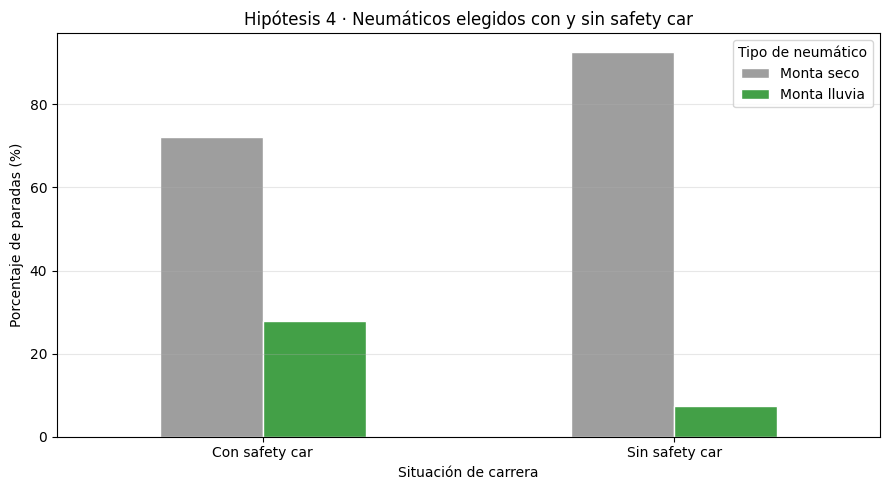


**Lectura de la hipótesis 4**

- Con safety car, el **27.9%**
  de las paradas monta neumáticos de lluvia.

- Sin safety car, el **7.4%**
  monta neumáticos de lluvia.

- Se registraron **75 paradas**
  con safety car donde se montaron neumáticos de lluvia.

- Las paradas con neumáticos de lluvia se distribuyen
  en **6 carreras**.

Los resultados muestran una asociación entre la presencia
del safety car y el uso de neumáticos INTERMEDIATE/WET.

Esto sugiere que parte de la relación observada
originalmente podría estar vinculada a condiciones
meteorológicas.

**Esta asociación no demuestra que el safety car cause
la elección del neumático.**


In [6]:
# ============================================================
# CORRECCIÓN 10 DE LA ENTREGA 2
# HIPÓTESIS 4: SAFETY CAR Y NEUMÁTICOS DE LLUVIA
# ============================================================

# Recuperamos la información descriptiva del Silver original.
# No agregamos safety_car_active a los modelos.

h4 = raw_pits[
    CLAVE + ["safety_car_active", "new_compound"]
].copy()

# Normalizamos la representación del indicador de safety car.
h4["safety_car"] = (
    h4["safety_car_active"]
    .astype("string")
    .str.lower()
    .eq("true")
)

# Clasificamos el compuesto elegido.
h4["tipo_neumatico"] = np.where(
    h4["new_compound"].isin(["INTERMEDIATE", "WET"]),
    "Monta lluvia",
    "Monta seco"
)

h4["situacion"] = np.where(
    h4["safety_car"],
    "Con safety car",
    "Sin safety car"
)


# ============================================================
# DISTRIBUCIÓN PORCENTUAL
# ============================================================

tabla_h4 = pd.crosstab(
    h4["situacion"],
    h4["tipo_neumatico"],
    normalize="index"
).mul(100).round(1)

# Incorporamos la cantidad de paradas y carreras.
tabla_h4["paradas"] = (
    h4["situacion"].value_counts()
)

tabla_h4["carreras"] = (
    h4.groupby("situacion")["session_key"].nunique()
)

display(tabla_h4)


# ============================================================
# ANÁLISIS DE LAS PARADAS CON LLUVIA
# ============================================================

lluvia_sc = h4[
    h4["tipo_neumatico"] == "Monta lluvia"
]

total_lluvia = len(lluvia_sc)

lluvia_con_sc = int(
    lluvia_sc["safety_car"].sum()
)

total_con_sc = int(
    h4["safety_car"].sum()
)

carreras_lluvia = (
    lluvia_sc["session_key"].nunique()
)

print(
    f"Paradas que montan INTERMEDIATE/WET: {total_lluvia}"
)

print(
    f"De ellas, {lluvia_con_sc} ocurrieron con safety car."
)

print(
    f"Carreras con paradas de lluvia: {carreras_lluvia}"
)

print(
    f"Paradas totales con safety car: {total_con_sc}"
)


# ============================================================
# GRÁFICO COMPARATIVO
# ============================================================

columnas_grafico = [
    "Monta seco",
    "Monta lluvia"
]

tabla_grafico = tabla_h4[
    columnas_grafico
]

ax = tabla_grafico.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#9e9e9e", "#43a047"],
    edgecolor="white"
)

ax.set_title(
    "Hipótesis 4 · Neumáticos elegidos con y sin safety car"
)

ax.set_xlabel("Situación de carrera")
ax.set_ylabel("Porcentaje de paradas (%)")

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

ax.legend(
    title="Tipo de neumático"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# INTERPRETACIÓN AUTOMÁTICA
# ============================================================

porcentaje_con_sc = tabla_h4.loc[
    "Con safety car",
    "Monta lluvia"
]

porcentaje_sin_sc = tabla_h4.loc[
    "Sin safety car",
    "Monta lluvia"
]

display(Markdown(f"""
**Lectura de la hipótesis 4**

- Con safety car, el **{porcentaje_con_sc:.1f}%**
  de las paradas monta neumáticos de lluvia.

- Sin safety car, el **{porcentaje_sin_sc:.1f}%**
  monta neumáticos de lluvia.

- Se registraron **{lluvia_con_sc} paradas**
  con safety car donde se montaron neumáticos de lluvia.

- Las paradas con neumáticos de lluvia se distribuyen
  en **{carreras_lluvia} carreras**.

Los resultados muestran una asociación entre la presencia
del safety car y el uso de neumáticos INTERMEDIATE/WET.

Esto sugiere que parte de la relación observada
originalmente podría estar vinculada a condiciones
meteorológicas.

**Esta asociación no demuestra que el safety car cause
la elección del neumático.**
"""))

In [7]:
# Movimiento de H4: si el safety car solo "trae" lluvia, en seco no debería cambiar el compuesto.
# Se repite la comparación SOLO con paradas que montan compuesto de seco.
seco = h4[h4.tipo_neumatico.eq('Monta seco')]
tabla_seco = (pd.crosstab(seco.situacion, seco.new_compound, normalize='index')
              .reindex(columns=['SOFT', 'MEDIUM', 'HARD']).mul(100).round(1))
tabla_seco['paradas'] = seco.situacion.value_counts()
display(tabla_seco)
brecha_hard_seco = (tabla_seco.loc['Sin safety car', 'HARD'] - tabla_seco.loc['Con safety car', 'HARD']) / 100
print(f'Brecha de HARD en seco (sin SC − con SC): {brecha_hard_seco:.3f}')

new_compound,SOFT,MEDIUM,HARD,paradas
situacion,,,,
Con safety car,26.3,38.1,35.6,194
Sin safety car,15.3,30.4,54.3,1912


Brecha de HARD en seco (sin SC − con SC): 0.187


### Interpretación de la hipótesis 4
- Parte de la asociación es lluvia: con safety car el **27,9 %** de las paradas monta INTERMEDIATE/WET, contra **7,4 %** sin safety car (75 de las 269 paradas con safety car son de lluvia, y vienen de 6 carreras).
- **Pero en seco la asociación sigue:** mirando solo paradas que montan compuesto de seco, con safety car se monta HARD en el **35,6 %** de las paradas y sin safety car en el **54,3 %** (brecha 0,187). Con safety car crecen SOFT y MEDIUM.
- Lectura de dominio: con safety car la parada cuesta menos tiempo y se aprovecha para poner un neumático para menos vueltas. En la Entrega 2 se comprobó que la brecha se mantiene sin las últimas 15 vueltas.
- Sigue siendo asociación, no causa.

**Decisión para el modelado:** `safety_car_active` queda fuera de los predictores, como pidió el docente. La usamos solo para leer errores: en la sección 10 se ve que muchas paradas que el modelo no anticipa ocurren con safety car.

## 2 · Variables históricas, adentro del pipeline
En la v5 las variables históricas se construían **antes**, afuera del objeto que se entrena. La consigna pide que todo lo derivado esté adentro. Ahora el primer paso del `Pipeline` es un transformador propio, `HistoriaCausal`:

- **Recibe** por cada vuelta a decidir solo quién, dónde y cuándo: `session_key`, `driver_number`, `lap_number`, `circuit_short_name`, `team_name`.
- **Lee** de un registro de carreras (`RegistroCarreras`, el equivalente a lo que la app vería en vivo) **solo vueltas anteriores de esa misma carrera**: la última vuelta previa del piloto y la vuelta t−1 del pelotón.
- **No aprende nada en `fit`**: no hay medias, máximos ni conteos del dataset. Por eso no puede filtrar información de un fold de validación al de entrenamiento.
- Después siguen, también adentro y reajustados en cada fold, la imputación, el escalado y el one-hot.

| Variable | Qué es | De dónde sale |
|---|---|---|
| `tyre_age_prev`, `compound_prev`, `position_prev` | edad y compuesto del neumático, y posición | última vuelta anterior del piloto |
| `stops_before` | paradas ya hechas | paradas en vueltas anteriores |
| `used_soft/medium/hard` | si ya usó ese compuesto en la carrera | máximo acumulado hasta la vuelta anterior |
| `field_*_prev` | proporción del pelotón en cada compuesto | vuelta t−1 de todos los pilotos |
| `track/air_temperature_prev`, `humidity_prev`, `rainfall_prev` | clima | última vuelta anterior |
| `lap_number`, `circuit_short_name`, `team_name` | momento de carrera, circuito y equipo | se conocen al empezar la vuelta |

Queda afuera, a propósito: la limpieza del dato de origen (celda anterior), la definición de qué vueltas se predicen (las que tienen al menos una vuelta previa del piloto con compuesto y edad conocidos) y las etiquetas. Ninguna de las tres calcula estadísticas sobre el dataset.

In [8]:
# Variables que entran a los modelos (todas se calculan DENTRO del pipeline, en el paso HistoriaCausal).
NUM = ['lap_number', 'tyre_age_prev', 'position_prev', 'stops_before', 'track_temperature_prev',
       'air_temperature_prev', 'humidity_prev', 'used_soft', 'used_medium', 'used_hard',
       'field_soft_prev', 'field_medium_prev', 'field_hard_prev', 'field_lluvia_prev']
CAT = ['compound_prev', 'circuit_short_name', 'team_name', 'rainfall_prev']
FEATURES = NUM + CAT
PROHIBIDAS = {'pit_stop', 'new_compound', 'current_compound', 'stint_number', 'pit_duration',
              'lane_duration', 'stop_duration', 'session_max_lap_observed', 'lap_duration',
              'gap_to_leader_raw', 'safety_car_active', 'yellow_flag_active', 'interval_raw'}
assert not (set(FEATURES) & PROHIBIDAS)
# Lo único que recibe el pipeline por cada vuelta a decidir: quién, dónde y en qué vuelta.
COLS_X = CLAVE + ['circuit_short_name', 'team_name']
COMPUESTOS_SECO = ['SOFT', 'MEDIUM', 'HARD']


class RegistroCarreras:
    """Registro de vueltas por carrera, como lo tendría la app durante la carrera.

    Guarda el estado ya calculado de cada carrera para no recalcularlo en cada fold.
    Al clonar el pipeline se comparte el mismo registro (no se copia).
    """
    COLUMNAS = ['session_key', 'driver_number', 'lap_number', 'pit_stop', 'current_compound',
                'tyre_age', 'position', 'rainfall', 'track_temperature', 'air_temperature', 'humidity']

    def __init__(self, vueltas):
        self.vueltas = vueltas[self.COLUMNAS].sort_values(CLAVE).reset_index(drop=True)
        self._piloto, self._peloton = {}, {}

    def __deepcopy__(self, memo):
        return self

    def estado(self, carreras):
        faltan = [c for c in pd.unique(carreras) if c not in self._piloto]
        if faltan:
            v = self.vueltas[self.vueltas.session_key.isin(faltan)].copy()
            gp = v.groupby(['session_key', 'driver_number'], sort=False)
            # Estado del piloto AL TERMINAR cada vuelta; se usa recién en una vuelta posterior.
            piloto = v[CLAVE].copy()
            for col, nueva in {'current_compound': 'compound_prev', 'tyre_age': 'tyre_age_prev',
                               'position': 'position_prev', 'rainfall': 'rainfall_prev',
                               'track_temperature': 'track_temperature_prev',
                               'air_temperature': 'air_temperature_prev', 'humidity': 'humidity_prev'}.items():
                piloto[nueva] = v[col]
            piloto['stops_before'] = gp['pit_stop'].cumsum().astype(int)
            for c in COMPUESTOS_SECO:
                piloto[f'used_{c.lower()}'] = (v.current_compound.eq(c).astype(float)
                                               .groupby([v.session_key, v.driver_number]).cummax())
            # Proporción del pelotón en cada compuesto al terminar cada vuelta.
            frac = pd.crosstab([v.session_key, v.lap_number], v.current_compound, normalize='index')
            for c in COMPUESTOS_SECO + ['INTERMEDIATE', 'WET']:
                if c not in frac.columns:
                    frac[c] = 0.0
            frac['LLUVIA'] = frac['INTERMEDIATE'] + frac['WET']
            frac = (frac[COMPUESTOS_SECO + ['LLUVIA']]
                    .rename(columns=lambda c: f'field_{c.lower()}_prev').reset_index())
            for c in faltan:
                self._piloto[c] = piloto[piloto.session_key.eq(c)]
                self._peloton[c] = frac[frac.session_key.eq(c)]
        lista = list(pd.unique(carreras))
        return (pd.concat([self._piloto[c] for c in lista], ignore_index=True),
                pd.concat([self._peloton[c] for c in lista], ignore_index=True))


class HistoriaCausal(BaseEstimator, TransformerMixin):
    """Primer paso del pipeline: arma las variables históricas de cada vuelta a decidir.

    Del registro lee SOLO vueltas anteriores de la misma carrera: la última vuelta previa
    del piloto y la vuelta t-1 del pelotón. fit no aprende nada (no hay estadísticas del dataset).
    """

    def __init__(self, registro=None):
        self.registro = registro

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        piloto, peloton = self.registro.estado(X['session_key'])
        base = X[COLS_X].copy()
        base['_orden'] = np.arange(len(base))
        base['lap_number'] = base['lap_number'].astype('int64')
        piloto = piloto.astype({'lap_number': 'int64'}).sort_values('lap_number')
        # allow_exact_matches=False: la última vuelta del piloto ESTRICTAMENTE anterior a la que se decide.
        salida = pd.merge_asof(base.sort_values('lap_number'), piloto, on='lap_number',
                               by=['session_key', 'driver_number'],
                               allow_exact_matches=False, direction='backward')
        peloton = peloton.assign(lap_number=peloton.lap_number.astype('int64') + 1)
        salida = salida.merge(peloton, on=['session_key', 'lap_number'], how='left')
        salida = salida.sort_values('_orden').reset_index(drop=True)
        salida['stops_before'] = salida['stops_before'].fillna(0)
        for c in COMPUESTOS_SECO:
            salida[f'used_{c.lower()}'] = salida[f'used_{c.lower()}'].fillna(0.0)
        salida.index = X.index
        return salida[FEATURES]


REGISTRO = RegistroCarreras(vueltas)

# Población: vueltas con al menos una vuelta previa del piloto con compuesto y edad conocidos.
# Es la definición de qué filas se predicen (no una estadística): mira una sola fila hacia atrás.
gpv = vueltas.groupby(['session_key', 'driver_number'], sort=False)
tiene_historia = gpv['current_compound'].shift(1).notna() & gpv['tyre_age'].shift(1).notna()
DESCRIPTIVAS = ['season', 'meeting_name', 'full_name', 'pit_stop', 'safety_car_active']
poblacion = vueltas.loc[tiene_historia, COLS_X + DESCRIPTIVAS].reset_index(drop=True)

objetivos = raw_pits[CLAVE + ['new_compound']].copy()
objetivos['objetivo_compuesto'] = objetivos['new_compound'].replace({'INTERMEDIATE': 'LLUVIA', 'WET': 'LLUVIA'})
poblacion = poblacion.merge(objetivos[CLAVE + ['objetivo_compuesto']], on=CLAVE, how='left', validate='one_to_one')
assert poblacion.loc[poblacion.pit_stop, 'objetivo_compuesto'].isin(ORDEN).all(), 'Paradas sin compuesto.'
print('Observaciones con historia:', len(poblacion), '| Paradas con compuesto:', int(poblacion.pit_stop.sum()))
display(poblacion.groupby('season').agg(vueltas=('pit_stop', 'size'), paradas=('pit_stop', 'sum'),
                                        carreras=('session_key', 'nunique')))
display(poblacion.loc[poblacion.pit_stop, 'objetivo_compuesto'].value_counts().reindex(ORDEN).to_frame('paradas'))

Observaciones con historia: 69472 | Paradas con compuesto: 2244


,vueltas,paradas,carreras
season,,,
2023,17534,657,16
2024,26151,785,24
2025,25787,802,24


,paradas
objetivo_compuesto,
SOFT,321
MEDIUM,631
HARD,1072
LLUVIA,220


### ¿Cómo sabemos que `HistoriaCausal` no usa el futuro?
Tres chequeos en la celda siguiente:
1. Se calculan las variables de todas las vueltas, solo para describir (el modelo las vuelve a calcular adentro).
2. **Borrar el futuro:** para 300 vueltas al azar se borra del registro todo lo que pasó desde esa vuelta en adelante, de todos los pilotos, y se recalculan. Si alguna variable mirara el futuro, cambiaría.
3. Se comparan con las variables que armaba la v5 afuera del pipeline: tienen que ser las mismas.

In [9]:
# Chequeo de fuga temporal del paso HistoriaCausal.
# 1) Se calculan las variables de todas las vueltas (solo para describir; el modelo las recalcula adentro).
estado = HistoriaCausal(REGISTRO).fit_transform(poblacion[COLS_X])
descr = pd.concat([poblacion, estado.drop(columns=['lap_number', 'circuit_short_name', 'team_name'])], axis=1)

# 2) Prueba de "borrar el futuro": para 300 vueltas al azar se borra del registro TODO lo que pasó
#    desde esa vuelta en adelante (todos los pilotos). Si alguna variable usara el futuro, cambiaría.
muestra = poblacion.sample(300, random_state=SEED)
cambios = 0
for i, fila in muestra.iterrows():
    sin_futuro = vueltas[~(vueltas.session_key.eq(fila.session_key) & vueltas.lap_number.ge(fila.lap_number))]
    recalculado = HistoriaCausal(RegistroCarreras(sin_futuro)).transform(muestra.loc[[i], COLS_X])
    cambios += int(not recalculado.astype(str).equals(estado.loc[[i]].astype(str)))
print(f'Vueltas cuyo vector de variables cambia al borrar el futuro: {cambios} de {len(muestra)}')
assert cambios == 0


# 3) Mismas variables que la v5: se compara contra construir_historia, que en la v5 corría afuera del pipeline.
def construir_historia_v5(tabla):
    v = tabla.sort_values(CLAVE).copy()
    gp = v.groupby(['session_key', 'driver_number'], sort=False)
    for col, nueva in {'current_compound': 'compound_prev', 'tyre_age': 'tyre_age_prev', 'position': 'position_prev',
                       'rainfall': 'rainfall_prev', 'track_temperature': 'track_temperature_prev',
                       'air_temperature': 'air_temperature_prev', 'humidity': 'humidity_prev'}.items():
        v[nueva] = gp[col].shift(1)
    v['stops_before'] = gp['pit_stop'].cumsum().astype(int) - v['pit_stop'].astype(int)
    for compuesto in COMPUESTOS_SECO:
        usado = v.current_compound.eq(compuesto).astype(float)
        v[f'used_{compuesto.lower()}'] = usado.groupby([v.session_key, v.driver_number]).transform(lambda s: s.shift(1).cummax())
    frac = pd.crosstab([v.session_key, v.lap_number], v.current_compound, normalize='index')
    for c in COMPUESTOS_SECO + ['INTERMEDIATE', 'WET']:
        if c not in frac.columns:
            frac[c] = 0.0
    frac['LLUVIA'] = frac['INTERMEDIATE'] + frac['WET']
    frac = frac[COMPUESTOS_SECO + ['LLUVIA']].rename(columns=lambda c: f'field_{c.lower()}_prev').reset_index()
    frac.lap_number += 1
    return v.merge(frac, on=['session_key', 'lap_number'], how='left', validate='many_to_one')


v5h = poblacion[CLAVE].merge(construir_historia_v5(vueltas), on=CLAVE, how='left')
distintas = [c for c in FEATURES if not (
    np.allclose(pd.to_numeric(v5h[c]).fillna(-999), pd.to_numeric(estado[c]).fillna(-999)) if c in NUM
    else v5h[c].astype(str).equals(estado[c].astype(str)))]
print('Variables distintas de las de la v5:', distintas or 'ninguna')
assert not distintas
print('Columnas que el pipeline recibe por vuelta:', COLS_X)
print('Columnas del registro que puede leer (solo vueltas anteriores):', RegistroCarreras.COLUMNAS)

Vueltas cuyo vector de variables cambia al borrar el futuro: 0 de 300


Variables distintas de las de la v5: ninguna
Columnas que el pipeline recibe por vuelta: ['session_key', 'driver_number', 'lap_number', 'circuit_short_name', 'team_name']
Columnas del registro que puede leer (solo vueltas anteriores): ['session_key', 'driver_number', 'lap_number', 'pit_stop', 'current_compound', 'tyre_age', 'position', 'rainfall', 'track_temperature', 'air_temperature', 'humidity']


**Resultado:** ninguna de las 300 vueltas cambia al borrar el futuro, y las 18 variables son idénticas a las de la v5. Pasar la historia adentro del pipeline no cambia los datos: cambia **dónde** se calculan. Así, el objeto que se entrena es el mismo que va a usar la app de la Entrega 4: recibe la vuelta y el registro de la carrera hasta ese momento.

## 2.1. Corrección de la hipótesis 1: edad del neumático y parada en boxes

En la Entrega 2 planteamos la siguiente hipótesis:

**H1: la edad del neumático influye en la decisión de realizar
una parada en boxes.**

Inicialmente utilizamos un boxplot para comparar la edad de
los neumáticos entre las vueltas con parada y sin parada.

A partir de la devolución del docente, reemplazamos ese
gráfico por un histograma.

El histograma permite observar con mayor claridad la
distribución de edades y detectar en qué intervalos
se concentran las paradas.

Para evitar utilizar información posterior al ingreso a boxes,
empleamos `tyre_age_prev`, que representa la edad del
neumático registrada en la vuelta anterior.

Como las vueltas sin parada son mucho más frecuentes,
normalizamos cada grupo por separado.

De esta manera, el gráfico compara la distribución
porcentual de ambos grupos sin que la diferencia de cantidad
de observaciones oculte sus patrones.

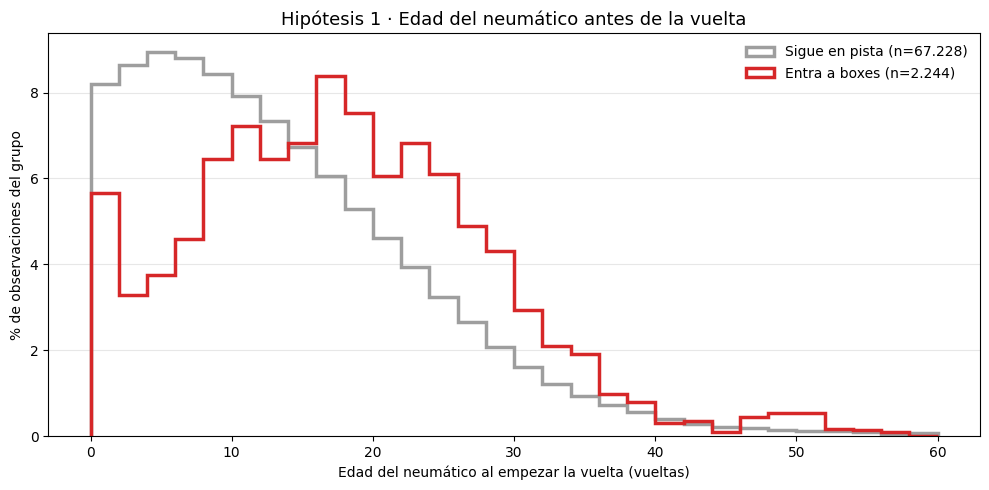

,count,25%,50%,75%
pit_stop,,,,
False,67228.0,5.0,11.0,19.0
True,2244.0,10.0,17.0,24.0


In [10]:
# ============================================================
# CORRECCIÓN 9 DE LA ENTREGA 2 · HIPÓTESIS 1: EDAD DEL NEUMÁTICO Y PARADAS
# ============================================================
datos_histograma = descr[['pit_stop', 'tyre_age_prev']].copy()
bins = np.arange(0, 61, 2)
fig, ax = plt.subplots(figsize=(10, 5))
for valor, etiqueta, color in [(False, 'Sigue en pista', '#9e9e9e'), (True, 'Entra a boxes', '#d62728')]:
    edades = datos_histograma.loc[datos_histograma.pit_stop.eq(valor), 'tyre_age_prev'].dropna()
    # Cada grupo se normaliza por separado: compara formas, no cantidades.
    ax.hist(edades, bins=bins, weights=np.full(len(edades), 100 / len(edades)), histtype='step',
            linewidth=2.5, color=color, label=f'{etiqueta} (n={len(edades):,})'.replace(',', '.'))
ax.set_title('Hipótesis 1 · Edad del neumático antes de la vuelta', fontsize=13)
ax.set_xlabel('Edad del neumático al empezar la vuelta (vueltas)')
ax.set_ylabel('% de observaciones del grupo')
ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
resumen_edades = datos_histograma.groupby('pit_stop')['tyre_age_prev'].describe()[['count', '25%', '50%', '75%']]
display(resumen_edades)

### Interpretación de la hipótesis 1
- Las vueltas con parada tienen neumáticos más viejos: mediana **17 vueltas** contra **11** en las vueltas sin parada (rango intercuartil 10–24 contra 5–19).
- Las dos distribuciones se superponen mucho y hay paradas con neumáticos de pocas vueltas (lluvia, safety car, daños). La edad sola no decide cuándo parar.
- El gráfico usa `tyre_age_prev`, la edad al empezar la vuelta: la edad de la vuelta del pit ya mostraba el neumático nuevo en parte de las paradas (corrección de la Entrega 2).

**Relación con el modelo:** en la sección 11, `tyre_age_prev` es la variable que más pesa en el modelo de parada.

## 3 · Métricas, pisos y validación
**`pit_stop` (sí/no):** métrica principal **F1 de la clase "para"**. Solo alrededor del 3 % de las vueltas tiene parada (3,3 % en 2023–2024, 3,1 % en 2025): un modelo que nunca para tiene 96,9 % de accuracy en 2025 y no sirve para nada. El F1 de la clase "para" combina precisión (de las alarmas, cuántas son paradas reales) y recall (de las paradas reales, cuántas se anticipan). Las dos cuestan: una parada de más pierde unos 20 segundos y posiciones; una parada que no se anticipa deja al piloto con un neumático gastado. Se informan también precisión y recall por separado.

**`new_compound` (4 clases):** **F1 macro**. SOFT (14 %) y LLUVIA (10 %) son chicas; el F1 macro les da el mismo peso que a HARD (48 %). Accuracy y accuracy balanceada como complemento.

**Pisos** (`DummyClassifier`, misma validación que todo lo demás):
- `pit_stop`: "nunca parar" da F1 = 0, pero el piso que hay que ganarle es **"siempre parar"**: atrapa todas las paradas con precisión 3 %, y su F1 es ≈ 0,064.
- `new_compound`: "siempre HARD" (la mayoritaria) y "al azar con las proporciones de cada clase".

**Partición:** entrenar y validar con 2023–2024, test en 2025: se entrena con temporadas pasadas y se usa en una nueva, como en la app. Adentro de 2023–2024, validación cruzada **por carrera**: todas las vueltas de una carrera quedan del mismo lado. Las vueltas de una carrera se parecen mucho entre sí (mismo circuito, clima y safety car); si quedaran de los dos lados, el modelo reconocería la carrera en lugar de anticipar una nueva.

In [11]:
train = poblacion[poblacion.season.lt(2025)].reset_index(drop=True)
test = poblacion[poblacion.season.eq(2025)].reset_index(drop=True)
assert set(train.session_key).isdisjoint(set(test.session_key))


def pipeline(modelo, nums=NUM, cats=CAT):
    preparar = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), list(nums)),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), list(cats))])
    return Pipeline([('historia', HistoriaCausal(REGISTRO)), ('preparar', preparar), ('modelo', modelo)])


def split_datos(tabla, solo_pits=False):
    v = tabla.loc[tabla.pit_stop].reset_index(drop=True) if solo_pits else tabla
    y = v.objetivo_compuesto if solo_pits else v.pit_stop.astype(int)
    return v[COLS_X].copy(), y, v.session_key


Xpit, ypit, gpit = split_datos(train)
Xpit_test, ypit_test, _ = split_datos(test)
Xcomp, ycomp, gcomp = split_datos(train, True)
Xcomp_test, ycomp_test, _ = split_datos(test, True)
print('Entrenamiento 2023-2024:', len(Xpit), 'vueltas,', int(ypit.sum()), 'paradas,', gpit.nunique(), 'carreras')
print('Test 2025:', len(Xpit_test), 'vueltas,', int(ypit_test.sum()), 'paradas,', test.session_key.nunique(), 'carreras')

Entrenamiento 2023-2024: 43685 vueltas, 1442 paradas, 40 carreras
Test 2025: 25787 vueltas, 802 paradas, 24 carreras


### 3.1 · El problema de los 5 pedazos de la v5
La v5 usaba `StratifiedGroupKFold(n_splits=5)` por carrera. Se revisa cuántas paradas de cada clase caen en cada fold de validación del modelo de compuesto y qué hace eso con el F1 macro.

In [12]:
# ¿Qué pasaba con la validación de la v5? StratifiedGroupKFold(5) por carrera, estratificando por fila.
cv_v5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
lluvia_por_carrera = train[train.pit_stop].groupby('session_key').objetivo_compuesto.apply(lambda s: s.eq('LLUVIA').sum())
print('Carreras de 2023-2024 con paradas a LLUVIA:', lluvia_por_carrera[lluvia_por_carrera > 0].to_dict())

log_ref = pipeline(LogisticRegression(C=0.003, max_iter=3000, class_weight='balanced', random_state=SEED))
filas = []
for i, (a, b) in enumerate(cv_v5.split(Xcomp, ycomp, gcomp), 1):
    pred = clone(log_ref).fit(Xcomp.iloc[a], ycomp.iloc[a]).predict(Xcomp.iloc[b])
    yv = ycomp.iloc[b]
    fila = {'fold': i, 'carreras': gcomp.iloc[b].nunique()}
    fila.update({f'n_{k}': int(yv.eq(k).sum()) for k in ORDEN})
    fila['LLUVIA predichas'] = int((pred == 'LLUVIA').sum())
    fila['clases que promedia f1_macro'] = len(set(yv) | set(pred))
    fila['F1 macro (sklearn)'] = f1_score(yv, pred, average='macro')
    fila['F1 macro (4 clases fijas)'] = f1_score(yv, pred, average='macro', labels=ORDEN, zero_division=0)
    filas.append(fila)
folds_v5 = pd.DataFrame(filas).set_index('fold')
display(folds_v5.round(3))
print('Desvío entre folds del F1 macro (v5):', round(folds_v5['F1 macro (sklearn)'].std(ddof=0), 3))

Carreras de 2023-2024 con paradas a LLUVIA: {9149: 57, 9531: 19, 9558: 23, 9636: 35}


,carreras,n_SOFT,n_MEDIUM,n_HARD,n_LLUVIA,LLUVIA predichas,clases que promedia f1_macro,F1 macro (sklearn),F1 macro (4 clases fijas)
fold,,,,,,,,,
1,7,38,79,126,0,6,4,0.426,0.426
2,7,90,65,122,57,16,4,0.303,0.303
3,9,12,66,135,54,76,4,0.704,0.704
4,8,23,84,173,0,0,3,0.555,0.416
5,9,25,67,203,23,20,4,0.380,0.380


Desvío entre folds del F1 macro (v5): 0.141


**Lectura.** En 2023–2024 hay solo **4 carreras con paradas a LLUVIA** (Países Bajos 2023; Canadá, Gran Bretaña y São Paulo 2024). Con 5 pedazos, como mínimo uno queda sin lluvia. Además `StratifiedGroupKFold` equilibra filas, no carreras, y puso dos carreras con lluvia en el mismo fold (el 3), así que **dos folds no tienen LLUVIA** (el 1 y el 4).

Eso hace que cada fold mida una cosa distinta:
- **Fold 4:** no hay LLUVIA y el modelo no la predijo. `f1_macro` promedia **3 clases** y da 0,555; con las 4 clases daría 0,416.
- **Fold 1:** no hay LLUVIA pero el modelo la predijo 6 veces. La clase LLUVIA entra con F1 = 0 y arrastra el promedio (0,426).
- **Folds con lluvia:** el número depende de qué carrera con lluvia tocó (0,303 contra 0,704).

Resultado: un desvío entre folds de **0,141** que no viene del modelo sino del reparto. Con ese ruido, ninguna comparación entre modelos se puede leer.

In [13]:
# Corrección: se reparten CARRERAS (no filas) en 4 pedazos, estratificando las carreras por "tuvo lluvia".
# Con 4 carreras con lluvia en 2023-2024, 4 pedazos es el máximo que deja una carrera con lluvia en cada uno.
# Toda carrera cae entera de un solo lado, igual que con StratifiedGroupKFold.
N_FOLDS = 4
carreras_train = (train.groupby('session_key')
                  .agg(lluvia=('objetivo_compuesto', lambda s: s.eq('LLUVIA').any()),
                       meeting_name=('meeting_name', 'first'), season=('season', 'first')).reset_index())


def folds_por_carrera(seed=SEED):
    asignacion = pd.Series(-1, index=carreras_train.session_key)
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for i, (_, b) in enumerate(skf.split(carreras_train, carreras_train.lluvia)):
        asignacion.iloc[b] = i
    return asignacion


def cv_por_carrera(grupos, seed=SEED):
    return PredefinedSplit(grupos.map(folds_por_carrera(seed)).values)


cvpit, cvcomp = cv_por_carrera(gpit), cv_por_carrera(gcomp)


def auditar_folds(y, gr, cv):
    filas = []
    for i, (a, b) in enumerate(cv.split(), 1):
        assert set(gr.iloc[a]).isdisjoint(set(gr.iloc[b]))
        fila = {'fold': i, 'filas_validacion': len(b), 'carreras_validacion': gr.iloc[b].nunique(),
                'carreras_compartidas': 0}
        fila.update({f'clase_{k}': int(v) for k, v in y.iloc[b].value_counts().items()})
        filas.append(fila)
    return pd.DataFrame(filas).fillna(0).set_index('fold')


print('PIT STOP:'); display(auditar_folds(ypit, gpit, cvpit))
print('COMPUESTO:'); display(auditar_folds(ycomp, gcomp, cvcomp)[['filas_validacion', 'carreras_validacion'] + [f'clase_{k}' for k in ORDEN]])
print('Carreras con lluvia por fold:', carreras_train.assign(fold=folds_por_carrera().values)
      .loc[lambda d: d.lluvia].set_index('fold').meeting_name.sort_index().to_dict())

PIT STOP:


,filas_validacion,carreras_validacion,carreras_compartidas,clase_0,clase_1
fold,,,,,
1,11074,10,0,10662,412
2,10921,10,0,10591,330
3,10221,10,0,9904,317
4,11469,10,0,11086,383


COMPUESTO:


,filas_validacion,carreras_validacion,clase_SOFT,clase_MEDIUM,clase_HARD,clase_LLUVIA
fold,,,,,,
1,412,10,85,92,178,57
2,330,10,14,55,226,35
3,317,10,31,83,180,23
4,383,10,58,131,175,19


Carreras con lluvia por fold: {0: 'Dutch Grand Prix', 1: 'São Paulo Grand Prix', 2: 'British Grand Prix', 3: 'Canadian Grand Prix'}


**Corrección.** Se reparten **carreras** en 4 pedazos de 10, estratificando las carreras por "tuvo paradas a LLUVIA". Así cada fold tiene exactamente una carrera con lluvia. Con 4 carreras con lluvia, 4 pedazos es el máximo que lo permite.
- Ninguna carrera queda de los dos lados (columna `carreras_compartidas` = 0), igual que con `StratifiedGroupKFold`.
- Cada fold tiene las 4 clases (LLUVIA entre 19 y 57 paradas), así que el F1 macro siempre promedia las mismas 4 clases.
- Las paradas por fold quedan parejas (317 a 412).
- Los dos modelos usan los **mismos pedazos**: la misma carrera nunca está en entrenamiento para un paso y en validación para el otro.
- Costo: cada entrenamiento ve 30 carreras en lugar de 32.

## 4 · Comparación de familias
Mismas columnas, mismos pedazos, media ± desvío de los 4 folds. La regresión logística es la referencia simple; árbol, bosque y boosting son las familias más complejas. Los hiperparámetros son moderados, los mismos de la v5. Se agrega el **F1 de entrenamiento**: si es mucho mayor que el de validación, el modelo memoriza.

In [14]:
def familias(objetivo):
    pisos = ({'Piso mayoría (nunca parar)': DummyClassifier(strategy='most_frequent'),
              'Piso siempre parar': DummyClassifier(strategy='constant', constant=1)}
             if objetivo == 'pit' else
             {'Piso mayoría (siempre HARD)': DummyClassifier(strategy='most_frequent'),
              'Piso estratificado (al azar)': DummyClassifier(strategy='stratified', random_state=SEED)})
    return {**pisos,
            'Regresión logística': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED),
            'Árbol': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
            'Random forest': RandomForestClassifier(n_estimators=120, max_depth=12, min_samples_leaf=15,
                                                    class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
            'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15,
                                                                   class_weight='balanced', random_state=SEED)}


def comparar(X, y, cv, metrica, objetivo):
    filas = []
    for nombre, estimador in familias(objetivo).items():
        r = cross_validate(pipeline(estimador), X, y, cv=cv, scoring=metrica, n_jobs=1,
                           return_train_score=True, error_score='raise')
        filas.append({'modelo': nombre, 'F1 validación': r['test_score'].mean(),
                      'desvío': r['test_score'].std(ddof=0), 'F1 entrenamiento': r['train_score'].mean(),
                      'folds': np.round(r['test_score'], 3).tolist()})
    return pd.DataFrame(filas).set_index('modelo').sort_values('F1 validación', ascending=False)


comparacion_pit = comparar(Xpit, ypit, cvpit, 'f1', 'pit')
comparacion_comp = comparar(Xcomp, ycomp, cvcomp, 'f1_macro', 'comp')
print('PIT STOP | F1 de la clase "para":'); display(comparacion_pit.round(4))
print('COMPUESTO | F1 macro:'); display(comparacion_comp.round(4))

PIT STOP | F1 de la clase "para":


,F1 validación,desvío,F1 entrenamiento,folds
modelo,,,,
Random forest,0.1364,0.0239,0.3008,"[0.119, 0.173, 0.112, 0.142]"
HistGradientBoosting,0.1275,0.0189,0.2574,"[0.113, 0.146, 0.104, 0.146]"
Árbol,0.1046,0.0111,0.1738,"[0.086, 0.116, 0.109, 0.108]"
Regresión logística,0.1002,0.0140,0.1455,"[0.079, 0.11, 0.096, 0.116]"
Piso siempre parar,0.0638,0.0051,0.0639,"[0.072, 0.059, 0.06, 0.065]"
Piso mayoría (nunca parar),0.0000,0.0000,0.0000,"[0.0, 0.0, 0.0, 0.0]"


COMPUESTO | F1 macro:


,F1 validación,desvío,F1 entrenamiento,folds
modelo,,,,
Random forest,0.5456,0.0931,0.7876,"[0.589, 0.671, 0.425, 0.497]"
HistGradientBoosting,0.4456,0.0875,0.9990,"[0.423, 0.362, 0.405, 0.592]"
Árbol,0.3893,0.0498,0.7413,"[0.383, 0.311, 0.439, 0.425]"
Regresión logística,0.3759,0.0115,0.7648,"[0.375, 0.392, 0.378, 0.359]"
Piso estratificado (al azar),0.2124,0.0150,0.2553,"[0.192, 0.206, 0.231, 0.221]"
Piso mayoría (siempre HARD),0.1730,0.0208,0.1725,"[0.151, 0.203, 0.181, 0.157]"


### Lectura de la comparación
**`pit_stop`:**
- El **random forest** es el mejor (0,136 ± 0,024), seguido por HistGradientBoosting (0,128), el árbol (0,105) y la logística (0,100).
- Todos superan al piso "siempre parar" (0,064); el bosque lo duplica.
- El bosque tiene la brecha más grande entre entrenamiento y validación (0,301 contra 0,136).

**`new_compound`:**
- El **random forest** (0,546 ± 0,093) supera a HistGradientBoosting (0,446), al árbol (0,389) y a la logística con valores por defecto (0,376). Los pisos dan 0,212 (al azar) y 0,173 (siempre HARD).
- El boosting **memoriza**: F1 de entrenamiento 0,999.
- La logística por defecto (C = 1) también sobreajusta: 0,765 en entrenamiento contra 0,376 en validación. Tiene un coeficiente por cada circuito y cada equipo y solo 1.442 paradas para estimarlos. El ajuste de la sección 5 lo corrige con más regularización.

**Finalistas:** la logística (la referencia obligatoria) y el bosque (el mejor en los dos objetivos). El boosting y el árbol no se ajustan: quedan debajo del bosque en los dos objetivos.

## 5 · Ajuste de hiperparámetros de los finalistas
`GridSearchCV` con los mismos pedazos por carrera; se muestra la **tabla completa**, con el F1 de validación, su desvío, el de entrenamiento y la brecha entre los dos.
- **Logística:** `C` (más chico = más regularización, modelo más simple) × `class_weight`.
- **Bosque:** profundidad × tamaño mínimo de hoja con `class_weight='balanced_subsample'`, más una configuración sin pesos para ver qué pasa sin compensar el desbalance.

In [15]:
def ajustar_finalistas(X, y, cv, score):
    grids = {
        'Regresión logística': (LogisticRegression(max_iter=5000, random_state=SEED),
                                {'modelo__C': [0.0001, 0.0003, 0.001, 0.003, 0.03, 0.3, 3],
                                 'modelo__class_weight': [None, 'balanced']}),
        'Random forest': (RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1),
                          [{'modelo__max_depth': [8, 12, 16], 'modelo__min_samples_leaf': [10, 25, 60],
                            'modelo__class_weight': ['balanced_subsample']},
                           {'modelo__max_depth': [16], 'modelo__min_samples_leaf': [25],
                            'modelo__class_weight': [None]}])}
    encontrados, filas = {}, []
    for nombre, (modelo, parametros) in grids.items():
        grid = GridSearchCV(pipeline(modelo), parametros, scoring=score, cv=cv, n_jobs=1, refit=True,
                            return_train_score=True, error_score='raise')
        grid.fit(X, y)
        encontrados[nombre] = grid
        t = pd.DataFrame(grid.cv_results_)
        t = pd.concat([pd.json_normalize(t['params']).rename(columns=lambda c: c.replace('modelo__', '')),
                       t[['mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']]], axis=1)
        t['brecha train-val'] = t.mean_train_score - t.mean_test_score
        t.insert(0, 'modelo', nombre)
        filas.append(t)
        print(nombre, '| mejor F1 CV:', round(grid.best_score_, 4), '|',
              {k.replace('modelo__', ''): v for k, v in grid.best_params_.items()})
    tabla = pd.concat(filas, ignore_index=True).sort_values(['modelo', 'rank_test_score']).reset_index(drop=True)
    display(tabla.round(4))
    return encontrados, tabla


print('AJUSTE PIT STOP'); grids_pit, tabla_grid_pit = ajustar_finalistas(Xpit, ypit, cvpit, 'f1')
print('AJUSTE COMPUESTO'); grids_comp, tabla_grid_comp = ajustar_finalistas(Xcomp, ycomp, cvcomp, 'f1_macro')

AJUSTE PIT STOP


Regresión logística | mejor F1 CV: 0.1098 | {'C': 0.001, 'class_weight': 'balanced'}


Random forest | mejor F1 CV: 0.1457 | {'class_weight': 'balanced_subsample', 'max_depth': 12, 'min_samples_leaf': 10}


,modelo,C,class_weight,mean_test_score,std_test_score,mean_train_score,rank_test_score,brecha train-val,max_depth,min_samples_leaf
0,Random forest,NaN,balanced_subsample,0.1457,0.0295,0.3176,1,0.1719,12.0,10.0
1,Random forest,NaN,balanced_subsample,0.1449,0.0264,0.2757,2,0.1309,12.0,25.0
2,Random forest,NaN,balanced_subsample,0.1426,0.0231,0.3951,3,0.2525,16.0,10.0
3,Random forest,NaN,balanced_subsample,0.1389,0.0188,0.3108,4,0.1719,16.0,25.0
4,Random forest,NaN,balanced_subsample,0.1379,0.0200,0.2378,5,0.0998,12.0,60.0
5,Random forest,NaN,balanced_subsample,0.1358,0.0188,0.2289,6,0.0931,8.0,10.0
6,Random forest,NaN,balanced_subsample,0.1357,0.0178,0.2216,7,0.0859,8.0,25.0
7,Random forest,NaN,balanced_subsample,0.1350,0.0190,0.2507,8,0.1157,16.0,60.0
8,Random forest,NaN,balanced_subsample,0.1305,0.0130,0.2077,9,0.0772,8.0,60.0
9,Random forest,NaN,None,0.0000,0.0000,0.0000,10,0.0000,16.0,25.0


AJUSTE COMPUESTO


Regresión logística | mejor F1 CV: 0.5005 | {'C': 0.0003, 'class_weight': 'balanced'}


Random forest | mejor F1 CV: 0.5608 | {'class_weight': 'balanced_subsample', 'max_depth': 12, 'min_samples_leaf': 10}


,modelo,C,class_weight,mean_test_score,std_test_score,mean_train_score,rank_test_score,brecha train-val,max_depth,min_samples_leaf
0,Random forest,NaN,balanced_subsample,0.5608,0.0639,0.8364,1,0.2756,12.0,10.0
1,Random forest,NaN,balanced_subsample,0.5599,0.0778,0.7374,2,0.1775,12.0,25.0
2,Random forest,NaN,balanced_subsample,0.5599,0.0778,0.7375,2,0.1776,16.0,25.0
3,Random forest,NaN,balanced_subsample,0.5599,0.0737,0.8393,4,0.2794,16.0,10.0
4,Random forest,NaN,balanced_subsample,0.5597,0.0786,0.7354,5,0.1757,8.0,25.0
5,Random forest,NaN,balanced_subsample,0.5455,0.0665,0.6689,6,0.1234,8.0,60.0
6,Random forest,NaN,balanced_subsample,0.5455,0.0665,0.6689,6,0.1234,12.0,60.0
7,Random forest,NaN,balanced_subsample,0.5455,0.0665,0.6689,6,0.1234,16.0,60.0
8,Random forest,NaN,balanced_subsample,0.5453,0.0823,0.8267,9,0.2814,8.0,10.0
9,Random forest,NaN,None,0.4831,0.0699,0.6683,10,0.1852,16.0,25.0


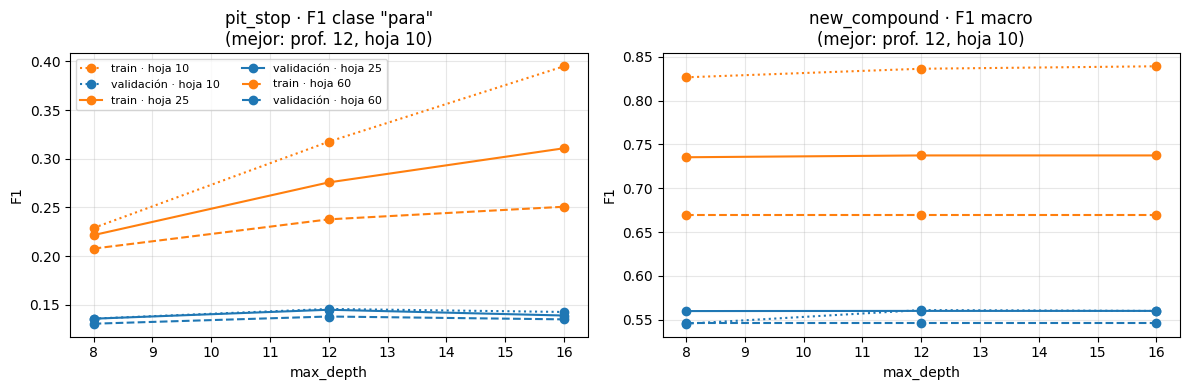

In [16]:
# Curva de validación del bosque: F1 de entrenamiento vs validación según la profundidad
# (con min_samples_leaf y class_weight del mejor). Si la de entrenamiento sube y la de validación no, sobreajusta.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (titulo, tabla, grid) in zip(axes, [('pit_stop · F1 clase "para"', tabla_grid_pit, grids_pit),
                                           ('new_compound · F1 macro', tabla_grid_comp, grids_comp)]):
    mejor = {k.replace('modelo__', ''): v for k, v in grid['Random forest'].best_params_.items()}
    t = tabla[(tabla.modelo == 'Random forest') & (tabla.class_weight == 'balanced_subsample')]
    for hoja, estilo in [(10, ':'), (25, '-'), (60, '--')]:
        s = t[t.min_samples_leaf == hoja].sort_values('max_depth')
        ax.plot(s.max_depth, s.mean_train_score, estilo, color='tab:orange', marker='o', label=f'train · hoja {hoja}')
        ax.plot(s.max_depth, s.mean_test_score, estilo, color='tab:blue', marker='o', label=f'validación · hoja {hoja}')
    ax.set(title=f'{titulo}\n(mejor: prof. {mejor["max_depth"]}, hoja {mejor["min_samples_leaf"]})',
           xlabel='max_depth', ylabel='F1')
    ax.grid(alpha=.3)
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

### Lectura del ajuste
**`pit_stop`:**
- Mejor bosque: profundidad 12 y hoja 10, con 0,146 ± 0,030. Las nueve configuraciones con pesos quedan entre 0,130 y 0,146: diferencias menores que el desvío. **Sin `class_weight` el bosque da 0**: nunca predice parada.
- Mejor logística: C = 0,001 balanceada, con 0,110. Sin balancear no pasa de 0,044.
- **Desbalance:** compensar con `class_weight` es imprescindible en este objetivo. Lo que cuesta se ve en la precisión: el modelo pasa a dar muchas alarmas (sección 7).

**`new_compound`:**
- Mejor logística: C = 0,0003 balanceada, con 0,500. Mucha regularización ayuda: con C = 3 llega a 0,78 en entrenamiento y cae a 0,38 en validación. C = 0,0001 ya baja (0,496), así que el óptimo está adentro de la grilla.
- Mejor bosque: profundidad 12 y hoja 10, con 0,561 ± 0,064.

**¿Sobreajusta el bosque?** Sí. En la curva, el F1 de entrenamiento sube con la profundidad (en `pit_stop`, de 0,21 a 0,40) y el de validación queda plano (0,13–0,146). Los árboles más profundos memorizan carreras de entrenamiento sin mejorar en carreras nuevas. Por eso el número que reportamos es siempre el de validación por carrera, nunca el de entrenamiento.

Un bosque más regularizado (hoja 25 o 60) da casi el mismo F1 de validación con menos brecha. Por ejemplo, en compuesto, hoja 25 da 0,560 con brecha 0,18 contra 0,28. Se dejó la mejor de la grilla, sin reglas extra; queda anotado como opción para la Entrega 4.

## 6 · Comparación pareada repetida y elección
Se repite la validación por carrera con 3 semillas (3 × 4 = 12 folds), con los mismos folds para los dos finalistas, y se mira la diferencia **bosque − logística** fold por fold.

**Regla (la de la cátedra):** el bosque se queda solo si su ventaja media supera el desvío de esas diferencias; si no, se queda la logística, que es más simple. Los 12 folds no son independientes: es una medida de estabilidad, no una prueba estadística. Las grillas y esta comparación usan los mismos datos, así que los dos números son un poco optimistas por igual.

In [17]:
def repetir_y_elegir(grids, X, y, g, score):
    puntajes = {k: [] for k in grids}
    for rep in range(3):
        cv = cv_por_carrera(g, seed=SEED + rep)
        for nombre, grid in grids.items():
            valores = cross_validate(clone(grid.best_estimator_), X, y, cv=cv, scoring=score,
                                     n_jobs=1, error_score='raise')['test_score']
            puntajes[nombre].extend(valores.tolist())
    t = pd.DataFrame(puntajes)
    d = t['Random forest'] - t['Regresión logística']
    resumen = pd.DataFrame({'media': t.mean(), 'desvío': t.std(ddof=0)})
    resumen.loc['Diferencia RF − logística'] = [d.mean(), d.std(ddof=0)]
    display(resumen.round(4))
    elegido = 'Random forest' if d.mean() > max(0, d.std(ddof=0)) else 'Regresión logística'
    display(Markdown(f'**Elección por validación:** `{elegido}`. Diferencia bosque − logística: '
                     f'**{d.mean():+.4f} ± {d.std(ddof=0):.4f}**; el bosque gana en **{(d > 0).mean():.0%}** '
                     f'de los {len(d)} folds.'))
    return elegido, grids[elegido].best_estimator_, resumen, d


print('PIT STOP'); elegido_pit, modelo_pit, res_pit, dif_pit = repetir_y_elegir(grids_pit, Xpit, ypit, gpit, 'f1')
print('COMPUESTO'); elegido_comp, modelo_comp, res_comp, dif_comp = repetir_y_elegir(grids_comp, Xcomp, ycomp, gcomp, 'f1_macro')

# Sobreajuste de los elegidos: F1 de entrenamiento vs validación con los hiperparámetros finales.
sobreajuste = []
for nombre, modelo, X, y, cv, sc in [('pit_stop · ' + elegido_pit, modelo_pit, Xpit, ypit, cvpit, 'f1'),
                                     ('new_compound · ' + elegido_comp, modelo_comp, Xcomp, ycomp, cvcomp, 'f1_macro')]:
    r = cross_validate(clone(modelo), X, y, cv=cv, scoring=sc, return_train_score=True)
    sobreajuste.append({'modelo': nombre, 'F1 entrenamiento': r['train_score'].mean(),
                        'F1 validación': r['test_score'].mean(), 'desvío validación': r['test_score'].std(ddof=0)})
sobreajuste = pd.DataFrame(sobreajuste).set_index('modelo')
sobreajuste['brecha'] = sobreajuste['F1 entrenamiento'] - sobreajuste['F1 validación']
display(sobreajuste.round(4))

PIT STOP


,media,desvío
Regresión logística,0.1103,0.0109
Random forest,0.1495,0.0292
Diferencia RF − logística,0.0392,0.0255


**Elección por validación:** `Random forest`. Diferencia bosque − logística: **+0.0392 ± 0.0255**; el bosque gana en **83%** de los 12 folds.

COMPUESTO


,media,desvío
Regresión logística,0.5136,0.0753
Random forest,0.5625,0.0882
Diferencia RF − logística,0.0489,0.0338


**Elección por validación:** `Random forest`. Diferencia bosque − logística: **+0.0489 ± 0.0338**; el bosque gana en **83%** de los 12 folds.

,F1 entrenamiento,F1 validación,desvío validación,brecha
modelo,,,,
pit_stop · Random forest,0.3176,0.1457,0.0295,0.1719
new_compound · Random forest,0.8364,0.5608,0.0639,0.2756


### Lectura y elección
- **`pit_stop` → random forest.** Diferencia **+0,039 ± 0,026**: supera el desvío y el bosque gana en 10 de 12 folds.
- **`new_compound` → random forest.** Diferencia **+0,049 ± 0,034**: también supera el desvío y gana en 10 de 12 folds.

**Esto cambia respecto de la v5**, que se quedaba con la logística para el compuesto (+0,059 ± 0,080). La ventaja media era parecida; lo que cambió es el desvío. Con los folds sin LLUVIA, el ruido entre folds (0,080) tapaba la diferencia. Con folds comparables baja a 0,034 y la ventaja del bosque se ve.

Lectura de dominio: elegir compuesto depende de combinaciones. Por ejemplo, "si todavía no usó MEDIUM y la pista está seca, MEDIUM", o "si el pelotón está en intermedios, LLUVIA". Un árbol las arma solo; una logística no, salvo que se las construyan como columnas.

**Sobreajuste de los elegidos:** en `pit_stop`, entrenamiento 0,318 contra validación 0,146; en `new_compound`, 0,836 contra 0,561. Los dos memorizan parte del entrenamiento (sección 5). El número que vale es el de validación.

## 7 · Umbral para recomendar parada (solo con validación de entrenamiento)
El `.predict()` usa el umbral 0,5. Con clases tan desparejas conviene revisarlo. Se calculan probabilidades **fuera de fold** sobre 2023–2024 (cada vuelta la predice un modelo que no vio su carrera) y se recorren umbrales de 0,10 a 0,90.

**Regla, fijada en la v5:** máximo F1 de la clase "para"; ante un empate, el umbral más alto, que da menos falsas alarmas. 2025 no se consulta. Los modelos con pesos de clase no están calibrados: 0,6 es un puntaje del modelo, no un 60 % de probabilidad real.

,umbral,F1,precision,recall,paradas_predichas
15,0.475,0.1403,0.0837,0.4320,7442
18,0.550,0.1402,0.0927,0.2871,4464
16,0.500,0.1398,0.0860,0.3738,6270
17,0.525,0.1384,0.0880,0.3245,5320
14,0.450,0.1379,0.0804,0.4840,8679
19,0.575,0.1370,0.0951,0.2448,3711
13,0.425,0.1335,0.0764,0.5305,10016
12,0.400,0.1307,0.0737,0.5791,11336


,F1,precision,recall,paradas_predichas
umbral,,,,
0.475,0.1403,0.0837,0.4320,7442
0.500,0.1398,0.0860,0.3738,6270


Umbral elegido SOLO en CV: 0.475 | paradas reales en entrenamiento: 1442


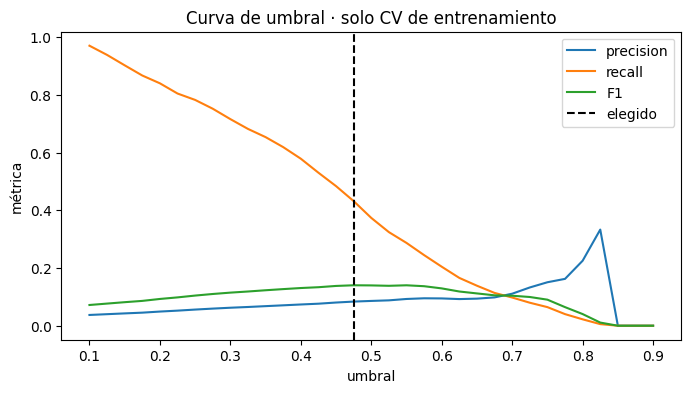

In [18]:
probas_pit_oof = cross_val_predict(clone(modelo_pit), Xpit, ypit, cv=cvpit, method='predict_proba', n_jobs=1)[:, 1]
umbrales = np.round(np.arange(.10, .901, .025), 3)
tabla_umbrales = pd.DataFrame([{'umbral': u, 'F1': f1_score(ypit, probas_pit_oof >= u, zero_division=0),
                                'precision': precision_score(ypit, probas_pit_oof >= u, zero_division=0),
                                'recall': recall_score(ypit, probas_pit_oof >= u, zero_division=0),
                                'paradas_predichas': int((probas_pit_oof >= u).sum())} for u in umbrales])
mejor_f1 = tabla_umbrales.F1.max()
UMBRAL_PIT = float(tabla_umbrales.loc[np.isclose(tabla_umbrales.F1, mejor_f1), 'umbral'].max())
display(tabla_umbrales.sort_values('F1', ascending=False).head(8).round(4))
display(tabla_umbrales.loc[tabla_umbrales.umbral.isin([0.5, UMBRAL_PIT])].set_index('umbral').round(4))
print('Umbral elegido SOLO en CV:', UMBRAL_PIT, '| paradas reales en entrenamiento:', int(ypit.sum()))
fig, ax = plt.subplots(figsize=(8, 4))
for col in ['precision', 'recall', 'F1']:
    ax.plot(tabla_umbrales.umbral, tabla_umbrales[col], label=col)
ax.axvline(UMBRAL_PIT, linestyle='--', color='k', label='elegido')
ax.set(xlabel='umbral', ylabel='métrica', title='Curva de umbral · solo CV de entrenamiento'); ax.legend(); plt.show()

### Lectura del umbral
- El máximo F1 fuera de fold es **0,1403 con umbral 0,475**: precisión 8,4 %, recall 43,2 %, 7.442 alarmas en 43.685 vueltas.
- **La curva es casi plana entre 0,45 y 0,575:** 0,50 da 0,1398 y 0,55 da 0,1402. A la milésima, el F1 es el mismo. Elegir el umbral ahí es elegir entre anticipar más paradas o dar menos falsas alarmas: con 0,55, la precisión sube a 9,3 % y el recall baja a 28,7 %.
- Se aplicó la regla tal como estaba escrita (0,475). No la cambiamos después de mirar el test, para no contaminarlo.
- Para la app conviene mostrar el umbral como una perilla de "sensibilidad" y no como un valor mágico.

## 8 · Columnas: cuáles sirven y qué pasa si se valida mal
**Ablación** con el modelo elegido de cada paso (mismos hiperparámetros y pedazos): se saca un grupo de columnas por vez y se mide el F1. Si la caída no supera el desvío, el grupo no está demostrando nada por sí solo.

In [19]:
# Ablación con el modelo ELEGIDO de cada etapa (mismos hiperparámetros, misma validación).
GRUPOS_ABLACION = {
    'tyre_age_prev': ['tyre_age_prev'], 'compound_prev': ['compound_prev'],
    'position_prev': ['position_prev'], 'stops_before': ['stops_before'],
    'used_* (compuestos ya usados)': ['used_soft', 'used_medium', 'used_hard'],
    'pelotón (field_*_prev)': ['field_soft_prev', 'field_medium_prev', 'field_hard_prev', 'field_lluvia_prev'],
    'clima (temperaturas, humedad, lluvia)': ['track_temperature_prev', 'air_temperature_prev', 'humidity_prev', 'rainfall_prev'],
    'circuito y equipo': ['circuit_short_name', 'team_name'],
    'lap_number': ['lap_number']}


def ablar(modelo, X, y, cv, scoring):
    filas = []
    base = cross_validate(clone(modelo), X, y, cv=cv, scoring=scoring)['test_score']
    filas.append({'experimento': 'Todas las variables', 'F1 medio': base.mean(), 'desvío': base.std(ddof=0), 'diferencia': 0.0})
    for nombre, cols in GRUPOS_ABLACION.items():
        est = clone(modelo)
        est.steps[1] = ('preparar', pipeline(None, [c for c in NUM if c not in cols],
                                             [c for c in CAT if c not in cols]).steps[1][1])
        r = cross_validate(est, X, y, cv=cv, scoring=scoring)['test_score']
        filas.append({'experimento': f'Sin {nombre}', 'F1 medio': r.mean(), 'desvío': r.std(ddof=0),
                      'diferencia': r.mean() - base.mean()})
    t = pd.DataFrame(filas).set_index('experimento')
    t['¿supera el desvío?'] = np.where(t.diferencia.abs() > t.loc['Todas las variables', 'desvío'], 'sí', 'no')
    return t


abl_pit = ablar(modelo_pit, Xpit, ypit, cvpit, 'f1')
abl_comp = ablar(modelo_comp, Xcomp, ycomp, cvcomp, 'f1_macro')
print(f'PIT STOP ({elegido_pit}):'); display(abl_pit.round(4))
print(f'COMPUESTO ({elegido_comp}):'); display(abl_comp.round(4))

PIT STOP (Random forest):


,F1 medio,desvío,diferencia,¿supera el desvío?
experimento,,,,
Todas las variables,0.1457,0.0295,0.0000,no
Sin tyre_age_prev,0.1383,0.0212,-0.0074,no
Sin compound_prev,0.1441,0.0339,-0.0016,no
Sin position_prev,0.1417,0.0315,-0.0040,no
Sin stops_before,0.1399,0.0198,-0.0058,no
Sin used_* (compuestos ya usados),0.1376,0.0274,-0.0081,no
Sin pelotón (field_*_prev),0.1386,0.0303,-0.0071,no
"Sin clima (temperaturas, humedad, lluvia)",0.1405,0.0212,-0.0052,no
Sin circuito y equipo,0.1365,0.0234,-0.0092,no


COMPUESTO (Random forest):


,F1 medio,desvío,diferencia,¿supera el desvío?
experimento,,,,
Todas las variables,0.5608,0.0639,0.0000,no
Sin tyre_age_prev,0.5570,0.0869,-0.0038,no
Sin compound_prev,0.5752,0.0741,0.0144,no
Sin position_prev,0.5445,0.0745,-0.0164,no
Sin stops_before,0.5331,0.0718,-0.0278,no
Sin used_* (compuestos ya usados),0.5770,0.0792,0.0161,no
Sin pelotón (field_*_prev),0.5121,0.0388,-0.0488,no
"Sin clima (temperaturas, humedad, lluvia)",0.5751,0.0806,0.0143,no
Sin circuito y equipo,0.5487,0.0720,-0.0122,no


### Lectura de la ablación
**`pit_stop`:** sacar cualquier grupo baja un poco el F1. Lo que más resta: `lap_number` (−0,016), circuito y equipo (−0,009), `used_*` (−0,008) y `tyre_age_prev` (−0,007). Ninguna caída supera el desvío (0,030). La información está repartida: `tyre_age_prev`, `lap_number` y `stops_before` cuentan historias parecidas ("cuánto hace que no paró"), así que al sacar una las otras la cubren.

**`new_compound`:**
- Lo que más resta es sacar el pelotón (−0,049) y `lap_number` (−0,046).
- Sacar `compound_prev`, `used_*` o el clima **sube** un poco el F1 (+0,014 a +0,016), pero dentro del desvío (0,064). Son las columnas que probamos y no aportaron.

**Decisión:** se dejan todas. Ninguna sobra con claridad, todas existen al decidir y sacar columnas por diferencias menores que el ruido sería elegir ruido.

In [20]:
# Contraprueba: ¿qué pasaría con el número si los pedazos se armaran AL AZAR por filas?
# Mismo modelo elegido, mismas columnas; solo cambia cómo se reparten las filas.
azar = []
for etapa, modelo, X, y, cv, sc in [('pit_stop', modelo_pit, Xpit, ypit, cvpit, 'f1'),
                                    ('new_compound', modelo_comp, Xcomp, ycomp, cvcomp, 'f1_macro')]:
    por_carrera = cross_validate(clone(modelo), X, y, cv=cv, scoring=sc)['test_score']
    al_azar = cross_validate(clone(modelo), X, y, scoring=sc,
                             cv=StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED))['test_score']
    azar.append({'etapa': etapa, 'F1 por carrera (el que reportamos)': por_carrera.mean(),
                 'F1 al azar por filas': al_azar.mean(), 'inflado': al_azar.mean() - por_carrera.mean()})
azar = pd.DataFrame(azar).set_index('etapa')
display(azar.round(4))

,F1 por carrera (el que reportamos),F1 al azar por filas,inflado
etapa,,,
pit_stop,0.1457,0.2498,0.1041
new_compound,0.5608,0.7531,0.1923


### ¿Y si los pedazos se armaran al azar?
Mismo modelo y mismas columnas, pero con `StratifiedKFold` por filas: el F1 de **`pit_stop` sube de 0,146 a 0,250** y el F1 macro de **`new_compound` de 0,561 a 0,753**.

El salto no es mejor modelo, es fuga. Con filas al azar, vueltas de la misma carrera quedan en entrenamiento y en validación, y el bosque aprende cosas como "en esta carrera, alrededor de la vuelta 20, paró todo el mundo" o "en esta carrera se puso HARD". Eso no sirve para anticipar una carrera nueva, que es el uso real. Por eso validamos por carrera.

## 9 · Evaluación final, una sola vez, sobre 2025
Recién acá se consulta 2025. Nada de esto se usa para cambiar modelos, columnas ni umbral. Se compara contra los pisos y se muestran las matrices de confusión normalizadas por fila (recall: de lo real, qué se predijo) y por columna (precisión: de lo predicho, qué era real), con el reporte por clase.

El modelo de compuesto se mide sobre las **paradas reales** de 2025: responde "si sabemos que para, ¿acierta el compuesto?". Eso no es el rendimiento del sistema completo (sección 12).

PIT STOP · TEST 2025


,modelo final,piso nunca parar,piso siempre parar
"F1 clase ""para""",0.1279,0.0000,0.0603
precision,0.0724,0.0000,0.0311
recall,0.5486,0.0000,1.0000
F1 macro,0.4969,0.4921,0.0302
accuracy,0.7674,0.9689,0.0311
vueltas con alarma,6077.0000,0.0000,25787.0000


              precision    recall  f1-score   support

       sigue       0.98      0.77      0.87     24985
        para       0.07      0.55      0.13       802

    accuracy                           0.77     25787
   macro avg       0.53      0.66      0.50     25787
weighted avg       0.95      0.77      0.84     25787

COMPUESTO · TEST 2025 (solo paradas reales)


,modelo final,piso mayoría
F1 macro,0.6378,0.1404
accuracy,0.6409,0.3903
accuracy balanceada,0.6549,0.2500


              precision    recall  f1-score   support

        SOFT       0.45      0.62      0.52       133
      MEDIUM       0.64      0.54      0.59       270
        HARD       0.74      0.70      0.72       313
      LLUVIA       0.68      0.76      0.72        86

    accuracy                           0.64       802
   macro avg       0.63      0.65      0.64       802
weighted avg       0.65      0.64      0.64       802



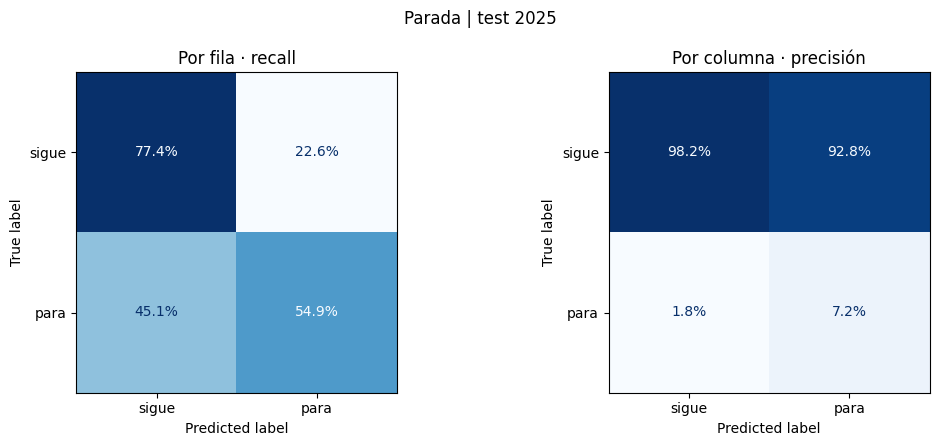

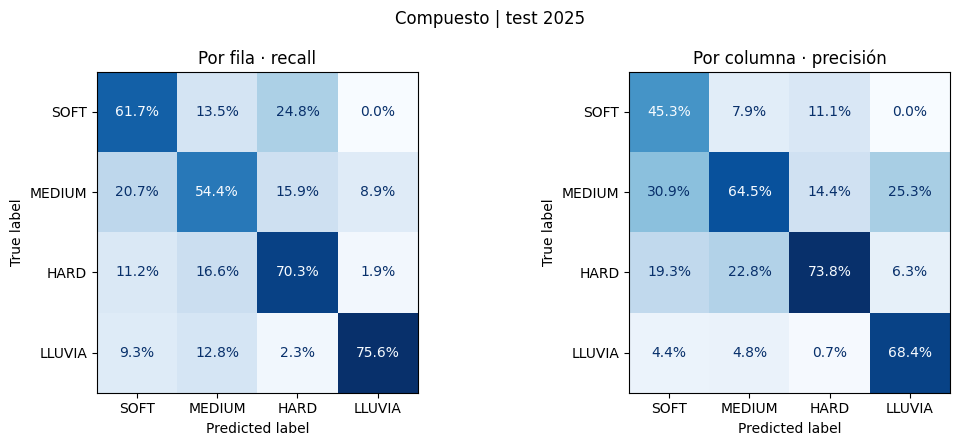

Cuentas absolutas (filas = real, columnas = predicho):


,pred sigue,pred para
real sigue,19348,5637
real para,362,440


,pred SOFT,pred MEDIUM,pred HARD,pred LLUVIA
real SOFT,82,18,33,0
real MEDIUM,56,147,43,24
real HARD,35,52,220,6
real LLUVIA,8,11,2,65


In [21]:
pred_pit = (modelo_pit.predict_proba(Xpit_test)[:, 1] >= UMBRAL_PIT).astype(int)
proba_pit_test = modelo_pit.predict_proba(Xpit_test)[:, 1]
pred_comp = modelo_comp.predict(Xcomp_test)
piso_comp = pipeline(DummyClassifier(strategy='most_frequent')).fit(Xcomp, ycomp).predict(Xcomp_test)
siempre = np.ones(len(ypit_test), dtype=int)


def metricas_pit(y, p):
    return {'F1 clase "para"': f1_score(y, p, zero_division=0), 'precision': precision_score(y, p, zero_division=0),
            'recall': recall_score(y, p, zero_division=0), 'F1 macro': f1_score(y, p, average='macro', zero_division=0),
            'accuracy': accuracy_score(y, p), 'vueltas con alarma': int(p.sum())}


print('PIT STOP · TEST 2025')
res_pit_test = metricas_pit(ypit_test, pred_pit)
display(pd.DataFrame({'modelo final': res_pit_test,
                      'piso nunca parar': metricas_pit(ypit_test, np.zeros_like(siempre)),
                      'piso siempre parar': metricas_pit(ypit_test, siempre)}).round(4))
print(classification_report(ypit_test, pred_pit, labels=[0, 1], target_names=['sigue', 'para'], zero_division=0))

print('COMPUESTO · TEST 2025 (solo paradas reales)')
res_comp_test = {'F1 macro': f1_score(ycomp_test, pred_comp, average='macro', zero_division=0),
                 'accuracy': accuracy_score(ycomp_test, pred_comp),
                 'accuracy balanceada': balanced_accuracy_score(ycomp_test, pred_comp)}
display(pd.DataFrame({'modelo final': res_comp_test, 'piso mayoría': {
    'F1 macro': f1_score(ycomp_test, piso_comp, average='macro', zero_division=0),
    'accuracy': accuracy_score(ycomp_test, piso_comp),
    'accuracy balanceada': balanced_accuracy_score(ycomp_test, piso_comp)}}).round(4))
print(classification_report(ycomp_test, pred_comp, labels=ORDEN, zero_division=0))


def matrices(y, pred, clases, titulo, nombres=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    for a, norm, nombre in zip(ax, ['true', 'pred'], ['Por fila · recall', 'Por columna · precisión']):
        ConfusionMatrixDisplay.from_predictions(y, pred, labels=clases, normalize=norm, cmap='Blues', ax=a,
                                                colorbar=False, values_format='.1%', display_labels=nombres)
        a.set_title(nombre)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


matrices(ypit_test, pred_pit, [0, 1], 'Parada | test 2025', ['sigue', 'para'])
matrices(ycomp_test, pred_comp, ORDEN, 'Compuesto | test 2025')
print('Cuentas absolutas (filas = real, columnas = predicho):')
display(pd.DataFrame(confusion_matrix(ypit_test, pred_pit), index=['real sigue', 'real para'], columns=['pred sigue', 'pred para']))
display(pd.DataFrame(confusion_matrix(ycomp_test, pred_comp, labels=ORDEN),
                     index=[f'real {c}' for c in ORDEN], columns=[f'pred {c}' for c in ORDEN]))

### Lectura del test
**`pit_stop`:**
- F1 de la clase "para" **0,128**, contra **0,060** del piso "siempre parar": el doble del piso.
- **Precisión 7,2 %:** de cada 14 alarmas, una es una parada real.
- **Recall 54,9 %:** anticipa 440 de las 802 paradas.
- La accuracy (76,7 %) queda debajo del 96,9 % de "nunca parar"; por eso no la usamos.
- El F1 de test queda un poco debajo del de validación (0,146): 2025 trae situaciones propias, como la salida en mojado de Bélgica o la lluvia de Australia.
- Para una orden automática de "entrá a boxes" no alcanza (5.637 falsas alarmas). Como señal de "se abrió la ventana de parada" dice algo (sección 10).

**`new_compound`** (sobre paradas reales):
- F1 macro **0,638** contra **0,140** del piso; accuracy 64,1 % contra 39,0 %.
- Por clase: HARD 0,72, LLUVIA 0,72, MEDIUM 0,59, SOFT 0,52.
- Las confusiones son entre compuestos vecinos: MEDIUM→SOFT (56), HARD→MEDIUM (52), MEDIUM→HARD (43).
- Por columna, SOFT tiene precisión 45 %: el modelo propone SOFT de más.

Los números de la v5 (F1 0,151, precisión 9,2 %) salieron de otra validación, otro umbral (0,55) y otro bosque. No se comparan para elegir.

## 10 · ¿Dónde se equivoca y por qué?
Para `pit_stop` se mira cada falsa alarma: ¿había una parada real poco después?, ¿las alarmas vienen sueltas o en rachas? También se compara el perfil de las paradas que el modelo anticipa (VP) con el de las que se le escapan (FN). `safety_car_active` se usa acá **solo para leer**: no está en el modelo.

In [22]:
# Lectura de los errores de pit_stop en 2025 (solo para leer: nada de esto cambia el modelo).
lect = descr[descr.season.eq(2025)].reset_index(drop=True).assign(pred=pred_pit, proba=proba_pit_test)
lect['sc'] = lect.safety_car_active.astype(str).str.lower().eq('true')
lect['ultima_vuelta'] = lect.groupby('session_key').lap_number.transform('max')
lect['tipo'] = np.select([lect.pit_stop & lect.pred.eq(1), ~lect.pit_stop & lect.pred.eq(1),
                          lect.pit_stop & lect.pred.eq(0)], ['VP', 'FP', 'FN'], 'VN')

# Distancia de cada vuelta a la parada real más cercana del mismo piloto (antes y después).
paradas_reales = lect.loc[lect.pit_stop, ['session_key', 'driver_number', 'lap_number']].rename(columns={'lap_number': 'vuelta_parada'})
orden = lect[['session_key', 'driver_number', 'lap_number']].reset_index().sort_values('lap_number')
pr = paradas_reales.sort_values('vuelta_parada')
prox = pd.merge_asof(orden, pr, left_on='lap_number', right_on='vuelta_parada', by=['session_key', 'driver_number'],
                     direction='forward', allow_exact_matches=False).set_index('index').sort_index()
prev = pd.merge_asof(orden, pr, left_on='lap_number', right_on='vuelta_parada', by=['session_key', 'driver_number'],
                     direction='backward', allow_exact_matches=False).set_index('index').sort_index()
lect['faltan_para_parar'] = prox.vuelta_parada - lect.lap_number
lect['desde_ultima_parada'] = lect.lap_number - prev.vuelta_parada

fp = lect[lect.tipo.eq('FP')]
categoria_fp = np.select([fp.faltan_para_parar.le(3), fp.faltan_para_parar.le(10)],
                         ['adelantada 1-3 vueltas', 'adelantada 4-10 vueltas'], 'sin parada en las 10 vueltas siguientes')
tabla_fp = pd.Series(categoria_fp).value_counts().to_frame('falsas alarmas')
tabla_fp['%'] = (tabla_fp['falsas alarmas'] / len(fp) * 100).round(1)
print(f'FALSAS ALARMAS (FP): {len(fp)} vueltas'); display(tabla_fp)
fp_sin = fp[pd.Series(categoria_fp, index=fp.index).eq('sin parada en las 10 vueltas siguientes')]
print('FP sin parada cercana: ¿el piloto ya no vuelve a parar en la carrera?',
      f'{fp_sin.faltan_para_parar.isna().mean():.1%} no vuelve a parar | mediana de edad del neumático {fp_sin.tyre_age_prev.median():.0f}',
      f'| {(fp_sin.ultima_vuelta - fp_sin.lap_number).le(15).mean():.1%} en las últimas 15 vueltas')

# Episodios de alarma: vueltas seguidas con alarma del mismo piloto. ¿Cuántos terminan en una parada real?
al = lect[lect.pred.eq(1)].sort_values(CLAVE).copy()
al['episodio'] = (al.groupby(['session_key', 'driver_number']).lap_number.diff().ne(1)).cumsum()
ep = al.groupby('episodio').agg(vueltas=('lap_number', 'size'), contiene_parada=('pit_stop', 'any'),
                                faltan=('faltan_para_parar', 'last'))
ep['termina_en_parada'] = ep.contiene_parada | ep.faltan.le(3)
print(f'Episodios de alarma: {len(ep)} (duración mediana {ep.vueltas.median():.0f} vueltas); '
      f'{ep.termina_en_parada.mean():.1%} contienen una parada real o la tienen en las 3 vueltas siguientes.')

# Paradas omitidas (FN) contra paradas detectadas (VP): ¿qué tienen distinto?
paradas = lect[lect.pit_stop].copy()
paradas['alarma_previa_1a3'] = [bool(((lect.session_key == r.session_key) & (lect.driver_number == r.driver_number) &
                                      lect.lap_number.between(r.lap_number - 3, r.lap_number - 1) & lect.pred.eq(1)).any())
                                for r in paradas.itertuples()]
perfil = paradas.groupby('tipo').agg(
    paradas=('pit_stop', 'size'),
    edad_mediana=('tyre_age_prev', 'median'),
    pct_safety_car=('sc', 'mean'),
    pct_monta_lluvia=('objetivo_compuesto', lambda s: s.eq('LLUVIA').mean()),
    pct_neumatico_menor_8=('tyre_age_prev', lambda s: s.lt(8).mean()),
    pct_ultimas_10_vueltas=('lap_number', lambda s: (paradas.loc[s.index, 'ultima_vuelta'] - s).lt(10).mean()),
    pct_segunda_parada_o_mas=('stops_before', lambda s: s.ge(1).mean()),
    pct_con_alarma_1a3_antes=('alarma_previa_1a3', 'mean')).T
print('PERFIL DE PARADAS DETECTADAS (VP) Y OMITIDAS (FN):'); display(perfil.round(3))
ventana = paradas.pred.eq(1) | paradas.alarma_previa_1a3
print(f'Paradas reales con alarma en la vuelta exacta: {paradas.pred.eq(1).mean():.1%} | '
      f'con alarma en la vuelta o en las 3 anteriores: {ventana.mean():.1%}')
print('Ejemplo de episodio largo de falsas alarmas:')
ej = ep[~ep.termina_en_parada].sort_values('vueltas', ascending=False).index[0]
display(al[al.episodio.eq(ej)][['meeting_name', 'full_name', 'lap_number', 'tyre_age_prev', 'compound_prev',
                                'stops_before', 'proba', 'faltan_para_parar']].head(12).round(3))

FALSAS ALARMAS (FP): 5637 vueltas


,falsas alarmas,%
sin parada en las 10 vueltas siguientes,2430,43.1
adelantada 4-10 vueltas,1992,35.3
adelantada 1-3 vueltas,1215,21.6


FP sin parada cercana: ¿el piloto ya no vuelve a parar en la carrera? 40.6% no vuelve a parar | mediana de edad del neumático 19 | 15.9% en las últimas 15 vueltas
Episodios de alarma: 641 (duración mediana 8 vueltas); 70.5% contienen una parada real o la tienen en las 3 vueltas siguientes.


PERFIL DE PARADAS DETECTADAS (VP) Y OMITIDAS (FN):


tipo,FN,VP
paradas,362.000,440.000
edad_mediana,11.000,22.000
pct_safety_car,0.279,0.011
pct_monta_lluvia,0.229,0.007
pct_neumatico_menor_8,0.320,0.032
pct_ultimas_10_vueltas,0.171,0.011
pct_segunda_parada_o_mas,0.696,0.257
pct_con_alarma_1a3_antes,0.039,0.948


Paradas reales con alarma en la vuelta exacta: 54.9% | con alarma en la vuelta o en las 3 anteriores: 56.6%
Ejemplo de episodio largo de falsas alarmas:


,meeting_name,full_name,lap_number,tyre_age_prev,compound_prev,stops_before,proba,faltan_para_parar
16937,Canadian Grand Prix,Esteban OCON,21,19.0,HARD,0,0.476,36.0
16938,Canadian Grand Prix,Esteban OCON,22,20.0,HARD,0,0.519,35.0
16939,Canadian Grand Prix,Esteban OCON,23,21.0,HARD,0,0.517,34.0
16940,Canadian Grand Prix,Esteban OCON,24,22.0,HARD,0,0.507,33.0
16941,Canadian Grand Prix,Esteban OCON,25,23.0,HARD,0,0.512,32.0
16942,Canadian Grand Prix,Esteban OCON,26,24.0,HARD,0,0.519,31.0
16943,Canadian Grand Prix,Esteban OCON,27,25.0,HARD,0,0.550,30.0
16944,Canadian Grand Prix,Esteban OCON,28,26.0,HARD,0,0.580,29.0
16945,Canadian Grand Prix,Esteban OCON,29,27.0,HARD,0,0.580,28.0
16946,Canadian Grand Prix,Esteban OCON,30,28.0,HARD,0,0.579,27.0


### Lectura de los errores de parada
**Falsas alarmas (5.637 vueltas).** No son errores al azar:
- El **21,6 %** llega 1 a 3 vueltas antes de una parada real y el **35,3 %**, 4 a 10 vueltas antes.
- El **43,1 %** no tiene parada en las 10 vueltas siguientes. De esas, en el 40,6 % el piloto ya no vuelve a parar: estrategias de una parada o stints finales largos, donde el equipo estira el neumático.
- Las alarmas vienen en **641 episodios** (rachas de vueltas seguidas, de 8 vueltas de mediana). El **70,5 %** contiene una parada real o la tiene en las 3 vueltas siguientes.

El modelo funciona como un detector de **"ventana de parada"**: cuando el neumático ya tiene muchas vueltas, la alarma se prende y queda prendida hasta que el piloto para. Lo que no sabe es la vuelta exacta. Esa depende de huecos en pista, tráfico, undercut y safety car, que no están en las columnas.

Ejemplo: Ocon en Canadá está en HARD desde el principio. La alarma se prende en la vuelta 21 (probabilidad ≈ 0,5–0,6) y la parada real llega 36 vueltas después: una estrategia de una parada con HARD largo.

**Paradas omitidas (362).** Tienen otro perfil que las detectadas:

| | omitidas (FN) | detectadas (VP) |
|---|---|---|
| con safety car | 27,9 % | 1,1 % |
| montan neumático de lluvia | 22,9 % | 0,7 % |
| con neumático de menos de 8 vueltas | 32,0 % | 3,2 % |
| en las últimas 10 vueltas | 17,1 % | 1,1 % |
| edad mediana del neumático | 11 vueltas | 22 vueltas |

Son paradas **reactivas**: safety car, lluvia, daños o cambios de último momento. No se pueden anticipar con la historia del neumático. Justo la variable que las explicaría (safety car) está fuera del modelo por decisión de la Entrega 2.

**Qué implica para una estrategia real:**
1. No usarlo como orden automática.
2. Sirve como indicador de que "se abrió la ventana"; el equipo elige la vuelta exacta.
3. Con safety car o lluvia el modelo está ciego, y la app tiene que avisarlo.
4. La tolerancia casi no cambia nada: con alarma en la vuelta exacta hay 54,9 % de las paradas, y con alarma en esa vuelta o en las 3 anteriores, 56,6 %. Lo que se escapa no se escapa por una vuelta, se escapa entero.

In [23]:
comp_lectura = descr[descr.season.eq(2025) & descr.pit_stop].reset_index(drop=True).assign(predicho=pred_comp)
comp_lectura['acierto'] = comp_lectura.objetivo_compuesto.eq(comp_lectura.predicho)
print('Acierto por compuesto de entrada:')
display(comp_lectura.groupby('compound_prev').acierto.agg(['size', 'mean']).round(3))
print('Acierto por carrera (las 6 peores):')
display(comp_lectura.groupby('meeting_name').acierto.agg(['size', 'mean']).sort_values('mean').head(6).round(3))
print('Errores más frecuentes (real → predicho):')
display(comp_lectura.loc[~comp_lectura.acierto].groupby(['objetivo_compuesto', 'predicho']).size()
        .sort_values(ascending=False).head(6).to_frame('paradas'))
print('Bélgica 2025, primeras paradas: todo el pelotón pasa de INTERMEDIATE a seco:')
display(comp_lectura[comp_lectura.meeting_name.str.contains('Belgian') & comp_lectura.compound_prev.eq('INTERMEDIATE')]
        [['full_name', 'lap_number', 'compound_prev', 'field_lluvia_prev', 'objetivo_compuesto', 'predicho']].head(6))
seco_sin_medium = comp_lectura[comp_lectura.objetivo_compuesto.ne('LLUVIA')]
print('En seco, ¿usa used_medium como regla? MEDIUM predicho según si ya usó MEDIUM:')
display(pd.crosstab(seco_sin_medium.used_medium.map({0.0: 'todavía no usó MEDIUM', 1.0: 'ya usó MEDIUM'}),
                    seco_sin_medium.predicho, normalize='index').round(3))

Acierto por compuesto de entrada:


,size,mean
compound_prev,,
HARD,207,0.522
INTERMEDIATE,114,0.614
MEDIUM,360,0.683
SOFT,121,0.744


Acierto por carrera (las 6 peores):


,size,mean
meeting_name,,
Belgian Grand Prix,26,0.000
Monaco Grand Prix,36,0.389
Qatar Grand Prix,41,0.415
Canadian Grand Prix,82,0.427
São Paulo Grand Prix,37,0.432
British Grand Prix,35,0.486


Errores más frecuentes (real → predicho):


,,paradas
objetivo_compuesto,predicho,
MEDIUM,SOFT,56
HARD,MEDIUM,52
MEDIUM,HARD,43
HARD,SOFT,35
SOFT,HARD,33
MEDIUM,LLUVIA,24


Bélgica 2025, primeras paradas: todo el pelotón pasa de INTERMEDIATE a seco:


,full_name,lap_number,compound_prev,field_lluvia_prev,objetivo_compuesto,predicho
386,Max VERSTAPPEN,12,INTERMEDIATE,1.0,MEDIUM,LLUVIA
387,Lando NORRIS,13,INTERMEDIATE,0.8,HARD,LLUVIA
388,Gabriel BORTOLETO,12,INTERMEDIATE,1.0,MEDIUM,LLUVIA
389,Isack HADJAR,13,INTERMEDIATE,0.8,MEDIUM,LLUVIA
391,Pierre GASLY,11,INTERMEDIATE,1.0,MEDIUM,LLUVIA
392,Kimi ANTONELLI,12,INTERMEDIATE,1.0,MEDIUM,LLUVIA


En seco, ¿usa used_medium como regla? MEDIUM predicho según si ya usó MEDIUM:


predicho,HARD,LLUVIA,MEDIUM,SOFT
used_medium,,,,
todavía no usó MEDIUM,0.017,0.128,0.791,0.064
ya usó MEDIUM,0.607,0.000,0.064,0.328


### Lectura de los errores de compuesto
- **Por compuesto de entrada:** acierta más cuando viene de SOFT (74 %) o MEDIUM (68 %) y menos cuando viene de HARD (52 %). Después de un HARD suele ser la segunda parada o más, con más opciones abiertas.
- **Bélgica 2025, 0 de 26.** Todo el pelotón larga en INTERMEDIATE y pasa a seco (MEDIUM) entre las vueltas 11 y 13. El modelo ve `field_lluvia_prev = 1` (todos en intermedios en la vuelta anterior) y responde LLUVIA. No tiene cómo saber que la pista se está secando: eso lo dirían los tiempos de vuelta recientes, que no son columnas del modelo. Es un caso de dominio claro y una mejora posible para la Entrega 4 (tiempos de las vueltas anteriores, que sí existen al decidir).
- También cuestan Mónaco (39 %) y Canadá (43 %). En carreras así, la estrategia depende más de la posición en pista y del clima del momento que de la historia del neumático.
- **Aprendió la regla de los dos compuestos:** en seco, si el piloto todavía no usó MEDIUM, propone MEDIUM el 79 % de las veces; si ya lo usó, propone HARD (61 %) o SOFT (33 %).

## 11 · ¿En qué se apoya cada modelo? Importancia por permutación en validación
En cada fold se entrena con el resto y, **en el fold de validación**, se desordena una variable por vez y se mide cuánto cae el F1. Se permutan las variables ya construidas por `HistoriaCausal`. Medirlo en validación evita premiar lo que el modelo memorizó en entrenamiento. Si dos variables cuentan lo mismo, la importancia se reparte entre ellas. Importancia no es causa.

In [24]:
def importancia_validacion(modelo, X, y, cv, scoring):
    resultados = []
    for tr, va in cv.split():
        est = clone(modelo).fit(X.iloc[tr], y.iloc[tr])
        # Se permutan las variables YA construidas (salida de HistoriaCausal) en el fold de validación.
        Xva = est[:1].transform(X.iloc[va])
        p = permutation_importance(est[1:], Xva, y.iloc[va], scoring=scoring, n_repeats=3,
                                   random_state=SEED, n_jobs=1)
        resultados.append(p.importances_mean)
    t = pd.DataFrame(resultados, columns=FEATURES)
    return pd.DataFrame({'caída F1 media': t.mean(), 'desvío': t.std(ddof=0),
                         'folds con caída positiva': (t > 0).sum()}).sort_values('caída F1 media', ascending=False)


print(f'PIT STOP ({elegido_pit}):')
imp_pit = importancia_validacion(modelo_pit, Xpit, ypit, cvpit, 'f1'); display(imp_pit.round(4))
print(f'COMPUESTO ({elegido_comp}):')
imp_comp = importancia_validacion(modelo_comp, Xcomp, ycomp, cvcomp, 'f1_macro'); display(imp_comp.round(4))

# Coeficientes de la logística de compuesto (variables estandarizadas): signo = hacia qué clase empuja.
if elegido_comp == 'Regresión logística':
    nombres = modelo_comp[1].get_feature_names_out()
    coef = pd.DataFrame(modelo_comp[-1].coef_.T, index=[n.split('__', 1)[1] for n in nombres],
                        columns=modelo_comp[-1].classes_)
    print('Coeficientes de la logística (numéricas estandarizadas), variables más importantes:')
    display(coef.loc[[c for c in ['used_medium', 'used_hard', 'used_soft', 'lap_number', 'field_lluvia_prev',
                                  'humidity_prev', 'tyre_age_prev', 'stops_before']]].round(3))

PIT STOP (Random forest):


,caída F1 media,desvío,folds con caída positiva
tyre_age_prev,0.0284,0.0095,4
stops_before,0.0255,0.0185,4
used_hard,0.0191,0.0093,4
compound_prev,0.0154,0.0089,4
position_prev,0.0058,0.0021,4
lap_number,0.0045,0.0056,3
circuit_short_name,0.0035,0.0072,3
team_name,0.0016,0.0020,3
used_soft,0.0014,0.0025,2
air_temperature_prev,0.0011,0.0053,2


COMPUESTO (Random forest):


,caída F1 media,desvío,folds con caída positiva
lap_number,0.0491,0.0354,3
field_lluvia_prev,0.0461,0.0602,2
field_soft_prev,0.0432,0.0250,4
field_hard_prev,0.0382,0.0077,4
used_hard,0.0259,0.0204,4
stops_before,0.0218,0.0166,4
used_medium,0.0140,0.0063,4
compound_prev,0.0110,0.0114,3
used_soft,0.0073,0.0156,2
humidity_prev,0.0068,0.0119,3


### Lectura de la importancia
**`pit_stop`:**
- Pesan `tyre_age_prev` (0,028, en los 4 folds), `stops_before` (0,026), `used_hard` (0,019) y `compound_prev` (0,015).
- Tiene sentido en carrera: cuanto más viejo el neumático y menos paradas hechas, más cerca de parar. Montar HARD suele anunciar el último stint.
- Es coherente con la H1 de la Entrega 2.
- Clima y pelotón dan cerca de 0 o negativo: no ayudan a elegir la vuelta.

**`new_compound`:**
- Pesan `lap_number` (0,049), `field_lluvia_prev` (0,046, pero solo en 2 de 4 folds: depende de qué carrera con lluvia le tocó al fold), `field_soft_prev` (0,043), `field_hard_prev` (0,038), `used_hard` (0,026), `stops_before` (0,022) y `used_medium` (0,014).
- El compuesto depende del momento de carrera (cerca del final, un neumático para menos vueltas), de lo que usa el resto del pelotón (seco o mojado, y qué compuesto funciona en esa carrera) y de lo que el piloto ya usó (regla de los dos compuestos).

**¿Alguna usa información futura?** No:
- `lap_number` se conoce al empezar la vuelta.
- Las `field_*_prev` son la vuelta t−1 del pelotón.
- `used_*`, `stops_before` y las `_prev` salen de vueltas anteriores del piloto.
- La prueba de borrar el futuro (sección 2) lo confirma para todas.
- Ninguna variable sorprende ni domina sola: sacar el pelotón baja el F1 del compuesto sin hundirlo (sección 8). Una columna con la respuesta adentro lo haría saltar.

## 12 · Sistema integrado: los dos pasos juntos sobre 2025
En cada vuelta, el sistema primero decide si recomienda parar (umbral de la sección 7). **Solo si recomienda parar**, propone un compuesto. Una parada real cuenta como acierto completo si el sistema recomendó parar en esa vuelta **y** el compuesto coincide.

In [25]:
prob_comp_total = modelo_comp.predict_proba(Xpit_test)
clases_comp = modelo_comp.named_steps['modelo'].classes_
comp_recomendado = clases_comp[np.argmax(prob_comp_total, axis=1)]
salida = test[CLAVE + ['season', 'meeting_name', 'full_name', 'pit_stop', 'objetivo_compuesto']].copy()
salida['recomendar_pit'] = pred_pit.astype(bool)
salida['compuesto_recomendado'] = np.where(salida.recomendar_pit, comp_recomendado, 'NO_APLICA')
detectadas = salida.pit_stop & salida.recomendar_pit
ambas_correctas = detectadas & salida.objetivo_compuesto.eq(salida.compuesto_recomendado)
res_sistema = pd.Series({
    'vueltas evaluadas': len(salida),
    'paradas reales': int(salida.pit_stop.sum()),
    'vueltas con parada recomendada': int(salida.recomendar_pit.sum()),
    'paradas reales correctamente detectadas': int(detectadas.sum()),
    'ambas decisiones correctas': int(ambas_correctas.sum()),
    'fracción de paradas reales con ambas decisiones correctas': ambas_correctas.sum() / salida.pit_stop.sum(),
    'acierto compuesto entre paradas reales detectadas': ambas_correctas.sum() / detectadas.sum(),
    'precisión del sistema (alarmas con parada y compuesto correctos)': ambas_correctas.sum() / salida.recomendar_pit.sum()})
display(res_sistema.to_frame('test 2025').round(4))

,test 2025
vueltas evaluadas,25787.0000
paradas reales,802.0000
vueltas con parada recomendada,6077.0000
paradas reales correctamente detectadas,440.0000
ambas decisiones correctas,342.0000
fracción de paradas reales con ambas decisiones correctas,0.4264
acierto compuesto entre paradas reales detectadas,0.7773
precisión del sistema (alarmas con parada y compuesto correctos),0.0563


In [26]:
# Descomposición: ambas correctas = (paradas detectadas / paradas reales) × (compuesto correcto / detectadas)
reales = salida[salida.pit_stop].copy()
reales['detectada'] = reales.recomendar_pit
reales['compuesto_ok_si_detectada'] = reales.objetivo_compuesto.eq(reales.compuesto_recomendado)
reales['compuesto_modelo_solo'] = pred_comp  # mismo orden: paradas reales de 2025
por_clase = reales.groupby('objetivo_compuesto').agg(
    paradas=('pit_stop', 'size'), detectadas=('detectada', 'mean'),
    compuesto_ok_entre_detectadas=('compuesto_ok_si_detectada', lambda s: s[reales.loc[s.index, 'detectada']].mean()),
    ambas_ok=('compuesto_ok_si_detectada', lambda s: (s & reales.loc[s.index, 'detectada']).mean()),
    compuesto_ok_modelo_solo=('compuesto_modelo_solo', lambda s: s.eq(reales.loc[s.index, 'objetivo_compuesto']).mean())
).reindex(ORDEN)
por_clase.loc['TOTAL'] = [len(reales), reales.detectada.mean(),
                          reales.loc[reales.detectada, 'compuesto_ok_si_detectada'].mean(),
                          (reales.detectada & reales.compuesto_ok_si_detectada).mean(),
                          reales.compuesto_modelo_solo.eq(reales.objetivo_compuesto).mean()]
print('Embudo por compuesto real (proporciones):'); display(por_clase.round(3))

# Referencias para leer el 2.º paso dentro del sistema: mismo detector, compuesto "siempre HARD".
hard_ok = (detectadas & salida.objetivo_compuesto.eq('HARD')).sum()
print(f'Con el mismo detector y compuesto siempre HARD: {hard_ok} paradas con ambas correctas '
      f'({hard_ok / detectadas.sum():.1%} de las detectadas) contra {int(ambas_correctas.sum())} del modelo.')
# ¿Qué recomienda en las falsas alarmas?
print('Compuesto recomendado en vueltas con falsa alarma:')
display(salida.loc[salida.recomendar_pit & ~salida.pit_stop, 'compuesto_recomendado'].value_counts(normalize=True)
        .reindex(ORDEN).round(3).to_frame('proporción'))
# Con tolerancia: parada real con alarma en esa vuelta o en las 3 anteriores y compuesto correcto en la última alarma.
s = salida.sort_values(CLAVE).reset_index(drop=True)
ok_tol = 0
for r in s[s.pit_stop].itertuples():
    v = s[(s.session_key == r.session_key) & (s.driver_number == r.driver_number) &
          s.lap_number.between(r.lap_number - 3, r.lap_number) & s.recomendar_pit]
    ok_tol += int(len(v) > 0 and v.compuesto_recomendado.iloc[-1] == r.objetivo_compuesto)
print(f'Con tolerancia de 3 vueltas de anticipación: {ok_tol} de {int(s.pit_stop.sum())} paradas '
      f'({ok_tol / s.pit_stop.sum():.1%}) con alarma y compuesto correctos.')
print('Ejemplo de respuestas del sistema:')
display(salida.loc[salida.recomendar_pit].head(8))

Embudo por compuesto real (proporciones):


,paradas,detectadas,compuesto_ok_entre_detectadas,ambas_ok,compuesto_ok_modelo_solo
objetivo_compuesto,,,,,
SOFT,133.0,0.496,0.455,0.226,0.617
MEDIUM,270.0,0.530,0.776,0.411,0.544
HARD,313.0,0.728,0.882,0.642,0.703
LLUVIA,86.0,0.035,0.000,0.000,0.756
TOTAL,802.0,0.549,0.777,0.426,0.641


Con el mismo detector y compuesto siempre HARD: 228 paradas con ambas correctas (51.8% de las detectadas) contra 342 del modelo.
Compuesto recomendado en vueltas con falsa alarma:


,proporción
compuesto_recomendado,
SOFT,0.055
MEDIUM,0.312
HARD,0.611
LLUVIA,0.021


Con tolerancia de 3 vueltas de anticipación: 347 de 802 paradas (43.3%) con alarma y compuesto correctos.
Ejemplo de respuestas del sistema:


,session_key,driver_number,lap_number,season,meeting_name,full_name,pit_stop,objetivo_compuesto,recomendar_pit,compuesto_recomendado
32,9693,1,34,2025,Australian Grand Prix,Max VERSTAPPEN,True,MEDIUM,True,MEDIUM
88,9693,4,34,2025,Australian Grand Prix,Lando NORRIS,True,HARD,True,MEDIUM
145,9693,5,34,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,HARD
146,9693,5,35,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,HARD
147,9693,5,36,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,HARD
148,9693,5,37,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,HARD
149,9693,5,38,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,HARD
150,9693,5,39,2025,Australian Grand Prix,Gabriel BORTOLETO,False,NaN,True,SOFT


### Lectura del sistema completo
**El sistema acierta parada y compuesto en 342 de las 802 paradas reales (42,6 %).** Se descompone así: anticipa el **54,9 %** de las paradas y, entre esas, acierta el compuesto en el **77,7 %** (0,549 × 0,777 = 0,426).

**El modelo de compuesto solo no es el recomendador.**
- Sobre todas las paradas reales, el modelo de compuesto acierta el 64,1 % (F1 macro 0,638). Ese número responde "si alguien me dice que hay parada".
- En el sistema, el compuesto solo llega a jugar en las paradas que el primer paso anticipa, que son sobre todo las planificadas en seco: se detecta el 72,8 % de las paradas a HARD, y ahí el compuesto acierta el 88,2 %.
- Las paradas a **LLUVIA** casi nunca se anticipan (3,5 %), así que el sistema no acierta **ninguna**, aunque el modelo de compuesto solo acierta el 75,6 % de ellas.
- SOFT se anticipa la mitad de las veces y ahí acierta el compuesto en el 45,5 %.

**Cuánto aporta el segundo paso:** con el mismo detector y "siempre HARD" habría 228 aciertos completos (51,8 % de las detectadas), contra 342 con el modelo. El modelo de compuesto suma 114 paradas.

**Del lado de las alarmas:** solo el **5,6 %** de las 6.077 vueltas con alarma son "parada real con el compuesto correcto". En las falsas alarmas el sistema propone sobre todo HARD (61 %) y MEDIUM (31 %). Con 3 vueltas de tolerancia sube apenas a 347 (43,3 %), por lo visto en la sección 10.

**Contra la v5 (256 de 802, 31,9 %):** la suba viene sobre todo de que hay **más alarmas**. El umbral pasa de 0,55 a 0,475 y las alarmas de 3.625 a 6.077, así que el recall sube de 41,8 % a 54,9 % y la precisión baja de 9,2 % a 7,2 %. No es un sistema mejor: es uno que avisa más.

## 13 · Qué se probó y qué no funcionó
Tabla armada con los resultados de validación de arriba (no con el test).

In [27]:
# Qué se probó y qué no funcionó: todo sale de las tablas de arriba (validación cruzada, sin test).
pd.set_option('display.max_colwidth', 120)
rf_none = tabla_grid_pit[(tabla_grid_pit.modelo == 'Random forest') & tabla_grid_pit.class_weight.isna()].mean_test_score.iloc[0]
log_none = tabla_grid_pit[(tabla_grid_pit.modelo == 'Regresión logística') & tabla_grid_pit.class_weight.isna()].mean_test_score.max()
u05 = tabla_umbrales.loc[np.isclose(tabla_umbrales.umbral, 0.5)].iloc[0]
uel = tabla_umbrales.loc[np.isclose(tabla_umbrales.umbral, UMBRAL_PIT)].iloc[0]
otro_pit = 'Regresión logística' if elegido_pit == 'Random forest' else 'Random forest'
otro_comp = 'Regresión logística' if elegido_comp == 'Random forest' else 'Random forest'
probado = pd.DataFrame([
    ['validación', 'StratifiedGroupKFold(5) de la v5', f'{int(folds_v5.n_LLUVIA.eq(0).sum())} folds sin LLUVIA; desvío del F1 macro entre folds {folds_v5["F1 macro (sklearn)"].std(ddof=0):.3f}',
     f'Se reemplaza por {N_FOLDS} pedazos de carreras, con 1 carrera con lluvia en cada uno'],
    ['validación', 'Pedazos al azar por filas', '; '.join(f'{e}: {r.iloc[1]:.3f} vs {r.iloc[0]:.3f} por carrera' for e, r in azar.iterrows()),
     'Descartado: infla el número porque la misma carrera queda de los dos lados'],
    ['pit_stop', 'Sin class_weight', f'F1: bosque {rf_none:.3f}, mejor logística {log_none:.3f}', 'Descartado: casi nunca predice parada'],
    ['pit_stop', 'Árbol / HistGradientBoosting', f"{comparacion_pit.loc['Árbol', 'F1 validación']:.3f} / {comparacion_pit.loc['HistGradientBoosting', 'F1 validación']:.3f}",
     'Quedan debajo del bosque; no se ajustan'],
    ['pit_stop', f'{otro_pit} ajustada', f"{res_pit.loc[otro_pit, 'media']:.3f} ± {res_pit.loc[otro_pit, 'desvío']:.3f}",
     f'Diferencia bosque − logística {dif_pit.mean():+.3f} ± {dif_pit.std(ddof=0):.3f} → queda {elegido_pit}'],
    ['pit_stop', 'Umbral 0,50 contra el elegido', f'F1 {u05.F1:.3f} vs {uel.F1:.3f}; precisión {u05.precision:.3f} vs {uel.precision:.3f}',
     f'Se usa {UMBRAL_PIT:.3f}; la curva es casi plana entre 0,45 y 0,575'],
    ['new_compound', 'Árbol / HistGradientBoosting', f"{comparacion_comp.loc['Árbol', 'F1 validación']:.3f} / {comparacion_comp.loc['HistGradientBoosting', 'F1 validación']:.3f}",
     'Quedan debajo del bosque; el boosting memoriza (F1 de entrenamiento ≈ 1)'],
    ['new_compound', f'{otro_comp} ajustada', f"{res_comp.loc[otro_comp, 'media']:.3f} ± {res_comp.loc[otro_comp, 'desvío']:.3f}",
     f'Diferencia bosque − logística {dif_comp.mean():+.3f} ± {dif_comp.std(ddof=0):.3f} → queda {elegido_comp}'],
    ['pit_stop', 'Quitar cada grupo de columnas', f'Ninguna caída supera el desvío ({abl_pit.loc["Todas las variables", "desvío"]:.3f})',
     'Se dejan todas: ninguna sobra con claridad y todas existen al decidir'],
    ['new_compound', 'Quitar cada grupo de columnas', f'Ninguna caída supera el desvío ({abl_comp.loc["Todas las variables", "desvío"]:.3f}); sacar el pelotón o lap_number es lo que más resta',
     'Se dejan todas'],
    ['ambas', 'gap_to_leader, safety_car_active', 'No se modelan (devolución de la Entrega 2)', 'Solo análisis descriptivo y lectura de errores'],
], columns=['etapa', 'qué se probó', 'resultado (CV)', 'decisión'])
display(probado)

,etapa,qué se probó,resultado (CV),decisión
0,validación,StratifiedGroupKFold(5) de la v5,2 folds sin LLUVIA; desvío del F1 macro entre folds 0.141,"Se reemplaza por 4 pedazos de carreras, con 1 carrera con lluvia en cada uno"
1,validación,Pedazos al azar por filas,pit_stop: 0.250 vs 0.146 por carrera; new_compound: 0.753 vs 0.561 por carrera,Descartado: infla el número porque la misma carrera queda de los dos lados
2,pit_stop,Sin class_weight,"F1: bosque 0.000, mejor logística 0.044",Descartado: casi nunca predice parada
3,pit_stop,Árbol / HistGradientBoosting,0.105 / 0.127,Quedan debajo del bosque; no se ajustan
4,pit_stop,Regresión logística ajustada,0.110 ± 0.011,Diferencia bosque − logística +0.039 ± 0.026 → queda Random forest
5,pit_stop,"Umbral 0,50 contra el elegido",F1 0.140 vs 0.140; precisión 0.086 vs 0.084,"Se usa 0.475; la curva es casi plana entre 0,45 y 0,575"
6,new_compound,Árbol / HistGradientBoosting,0.389 / 0.446,Quedan debajo del bosque; el boosting memoriza (F1 de entrenamiento ≈ 1)
7,new_compound,Regresión logística ajustada,0.514 ± 0.075,Diferencia bosque − logística +0.049 ± 0.034 → queda Random forest
8,pit_stop,Quitar cada grupo de columnas,Ninguna caída supera el desvío (0.030),Se dejan todas: ninguna sobra con claridad y todas existen al decidir
9,new_compound,Quitar cada grupo de columnas,Ninguna caída supera el desvío (0.064); sacar el pelotón o lap_number es lo que más resta,Se dejan todas


**En resumen:**
- Lo que no funcionó: entrenar sin compensar el desbalance (no predice paradas), el árbol y el boosting (debajo del bosque; el boosting memoriza), la logística sin regularizar en compuesto y validar al azar (infla el número).
- Sacar columnas tampoco: ninguna mejora supera el ruido.
- Lo que sí funcionó: el bosque con pesos de clase, por más que el desvío en los dos pasos.
- Lo que no resolvimos: anticipar paradas reactivas (safety car, lluvia) y detectar cuándo una pista mojada se seca.

## 14 · Exportación y contrato de inferencia para la Entrega 4
Se guardan los dos pipelines entrenados y un archivo con columnas, umbral y clases. Cada pipeline recibe la vuelta a decidir (`session_key`, `driver_number`, `lap_number`, `circuit_short_name`, `team_name`) y, como primer paso, arma la historia con el registro de la carrera.

El registro no se guarda dentro del modelo: la app le pasa el de la carrera en curso con `modelo.set_params(historia__registro=RegistroCarreras(vueltas_hasta_ahora))`. Para cargar los `.joblib`, las clases `RegistroCarreras` e `HistoriaCausal` tienen que estar definidas en la app.

`compuesto_recomendado` solo tiene sentido cuando la probabilidad de parada supera el umbral.

**Límites:** lluvia concentrada en pocas carreras, safety car fuera del modelo, precisión baja del detector de parada, decisiones reales que dependen de neumáticos disponibles y de la estrategia del equipo (no observados), y un test 2025 ya consultado por versiones anteriores.

In [28]:
RUTA_SALIDA = Path('/content') if Path('/content').is_dir() else Path.cwd()
# El registro de carreras no se guarda dentro del modelo: la app le pasa el de la carrera en curso con
# modelo.set_params(historia__registro=RegistroCarreras(vueltas_hasta_ahora)). Las clases
# RegistroCarreras e HistoriaCausal tienen que estar definidas (importadas) en la app para cargar el joblib.
for nombre, modelo in [('f1_modelo_pit_stop.joblib', modelo_pit), ('f1_modelo_new_compound.joblib', modelo_comp)]:
    modelo.set_params(historia__registro=None)
    joblib.dump(modelo, RUTA_SALIDA / nombre)
    modelo.set_params(historia__registro=REGISTRO)
joblib.dump({'columnas_entrada': COLS_X, 'features': FEATURES, 'numericas': NUM, 'categoricas': CAT,
             'umbral_pit': UMBRAL_PIT, 'clases_compuesto': list(clases_comp), 'seed': SEED,
             'entrenamiento': '2023-2024', 'test': '2025', 'scikit_learn': sklearn.__version__},
            RUTA_SALIDA / 'f1_metadata_inferencia.joblib')

# Prueba del contrato: cargar, enchufar un registro y predecir una vuelta de 2025.
cargado = joblib.load(RUTA_SALIDA / 'f1_modelo_pit_stop.joblib').set_params(historia__registro=REGISTRO)
assert np.allclose(cargado.predict_proba(Xpit_test.head(50))[:, 1], proba_pit_test[:50])
print('Artefactos guardados y probados:', *sorted(str(p) for p in RUTA_SALIDA.glob('f1_*.joblib')), sep='\n - ')

Artefactos guardados y probados:
 - /workspace/e3/final_run/f1_metadata_inferencia.joblib
 - /workspace/e3/final_run/f1_modelo_new_compound.joblib
 - /workspace/e3/final_run/f1_modelo_pit_stop.joblib


## 15 · Resumen generado con los números de esta corrida

In [29]:
display(Markdown(f"""**Resumen verificable — salida de esta ejecución**

- **Objetivos:** parada por vuelta (`pit_stop`) y compuesto si se para (`new_compound`), con las mismas variables históricas calculadas dentro del pipeline.
- **Validación:** 2023-2024 con {N_FOLDS} pedazos de carreras enteras (una carrera con lluvia en cada uno); 2025 una sola vez al final.
- **Parada:** `{elegido_pit}`, umbral por CV **{UMBRAL_PIT:.3f}**. CV F1 {sobreajuste.iloc[0]['F1 validación']:.3f} ± {sobreajuste.iloc[0]['desvío validación']:.3f} contra el piso "siempre parar" {comparacion_pit.loc['Piso siempre parar', 'F1 validación']:.3f}. Test 2025: F1 **{res_pit_test['F1 clase "para"']:.3f}**, precisión **{res_pit_test['precision']:.1%}**, recall **{res_pit_test['recall']:.1%}** (piso siempre parar: {metricas_pit(ypit_test, siempre)['F1 clase "para"']:.3f}).
- **Compuesto:** `{elegido_comp}`. CV F1 macro {sobreajuste.iloc[1]['F1 validación']:.3f} ± {sobreajuste.iloc[1]['desvío validación']:.3f} contra piso {comparacion_comp.loc['Piso mayoría (siempre HARD)', 'F1 validación']:.3f}. Test 2025 (sobre paradas reales): F1 macro **{res_comp_test['F1 macro']:.3f}**, accuracy **{res_comp_test['accuracy']:.1%}**.
- **Sistema completo:** **{int(ambas_correctas.sum())}** de **{int(salida.pit_stop.sum())}** paradas reales con parada y compuesto correctos (**{ambas_correctas.sum() / salida.pit_stop.sum():.1%}**); con 3 vueltas de tolerancia, {ok_tol} ({ok_tol / salida.pit_stop.sum():.1%}).
- **Fuga:** las variables se arman en `HistoriaCausal` dentro del pipeline; borrar el futuro no cambia ninguna (0 de 300). Con pedazos al azar por filas el F1 subiría a {azar.iloc[0, 1]:.3f} (parada) y {azar.iloc[1, 1]:.3f} (compuesto): ese salto es la fuga que evita partir por carrera.
"""))

**Resumen verificable — salida de esta ejecución**

- **Objetivos:** parada por vuelta (`pit_stop`) y compuesto si se para (`new_compound`), con las mismas variables históricas calculadas dentro del pipeline.
- **Validación:** 2023-2024 con 4 pedazos de carreras enteras (una carrera con lluvia en cada uno); 2025 una sola vez al final.
- **Parada:** `Random forest`, umbral por CV **0.475**. CV F1 0.146 ± 0.030 contra el piso "siempre parar" 0.064. Test 2025: F1 **0.128**, precisión **7.2%**, recall **54.9%** (piso siempre parar: 0.060).
- **Compuesto:** `Random forest`. CV F1 macro 0.561 ± 0.064 contra piso 0.173. Test 2025 (sobre paradas reales): F1 macro **0.638**, accuracy **64.1%**.
- **Sistema completo:** **342** de **802** paradas reales con parada y compuesto correctos (**42.6%**); con 3 vueltas de tolerancia, 347 (43.3%).
- **Fuga:** las variables se arman en `HistoriaCausal` dentro del pipeline; borrar el futuro no cambia ninguna (0 de 300). Con pedazos al azar por filas el F1 subiría a 0.250 (parada) y 0.753 (compuesto): ese salto es la fuga que evita partir por carrera.


## 16 · Para la defensa: respuestas cortas a lo que se pregunta
- **¿Por qué esa métrica?** Solo alrededor del 3 % de las vueltas es parada: la accuracy premia a "nunca parar" con 96,9 % en 2025. El F1 de la clase "para" mira las paradas y combina precisión (no parar de más) con recall (no perderse paradas). En compuesto usamos F1 macro porque SOFT y LLUVIA son chicas y valen lo mismo que HARD.
- **¿Cuánto le gana al piso?** En validación, parada 0,146 contra 0,064 de "siempre parar"; en test, 0,128 contra 0,060. Compuesto 0,561 contra 0,173 en validación y 0,638 contra 0,140 en test. Es el doble del piso en parada, pero con precisión del 7 % no alcanza para una orden automática. Sí alcanza como aviso de "ventana abierta".
- **¿Por qué los pedazos así?** Las vueltas de una carrera se parecen entre sí. Repartiendo carreras, la misma nunca queda de los dos lados. Al azar el número sube a 0,250 y 0,753, y esa diferencia es la fuga. Usamos 4 pedazos para que cada uno tenga una de las 4 carreras con lluvia: con 5, dos folds quedaban sin LLUVIA y el F1 macro de cada fold medía cosas distintas.
- **¿Por qué el bosque y no la logística?** Porque le gana por más que el desvío en los dos pasos: +0,039 ± 0,026 en parada y +0,049 ± 0,034 en compuesto. En compuesto la v5 elegía la logística porque los folds sin lluvia inflaban el desvío a 0,080.
- **Una confusión concreta:** Bélgica 2025. Todos pasan de intermedios a MEDIUM en la vuelta 11–13 y el modelo dice LLUVIA, porque en la vuelta anterior todo el pelotón estaba en intermedios. Le falta una señal de que la pista se seca. En parada: Ocon en Canadá, con alarma 36 vueltas antes de su única parada.
- **¿La columna que más pesa es fuga?** En parada pesa `tyre_age_prev`, la edad al **empezar** la vuelta, que sale de la vuelta anterior. Borramos todo el futuro de 300 vueltas y ninguna variable cambió. Además, la edad de la vuelta del pit, que sí tenía fuga parcial, no se usa.